# Uso, procesamiento y visualización de grandes volúmenes de datos

## Regresión de la temperatura máxima del día siguiente en Estados Unidos con PySpark MLlib

**Materia:** Inteligencia Artificial Avanzada para la Ciencia de Datos  
**Estudiante:** Juan Pablo Arteaga Patiño

En este proyecto trabajo con los registros diarios de estaciones meteorológicas de Estados Unidos que publica NOAA en la base *Global Historical Climatology Network – Daily* (GHCN-D). La pregunta que guía el modelo es:

> **¿Qué tan bien se puede anticipar la temperatura máxima de mañana en una estación a partir de lo observado hoy y durante la última semana, la ubicación de la estación y la época del año?**

Es un problema de **regresión**: la variable de respuesta es continua (grados Celsius) y el error se interpreta directamente en grados. Además, el problema tiene un competidor natural muy difícil de superar, la **persistencia** ("mañana hará la misma temperatura que hoy"). Por eso la evaluación compara siempre contra esa referencia: un modelo solo es útil si la mejora respecto a ella es real.

El trabajo está organizado por capas de datos (bronce → plata → oro). Primero se convierten los archivos originales a Parquet, después se limpian y se reestructuran, y por último se construyen las variables para el modelo. El procesamiento se hace con Spark sobre **toda** la base. El entrenamiento usa una muestra de filas por razones de tiempo y memoria que explico en la sección

## 1. Configuración del ambiente en Google Colab

**Decisiones**

- **Spark en modo local dentro de Colab.** Colab ofrece una sola máquina virtual con pocos núcleos y unos 12 GB de RAM, así que no es un clúster. Aun así, la API de PySpark es la misma que en un clúster: las transformaciones son perezosas, el plan se optimiza antes de ejecutarse y el trabajo se reparte en particiones. Lo que se aprende aquí se traslada sin cambios a un clúster administrado (Databricks, EMR, Dataproc). Lo que no puedo demostrar en Colab es el escalamiento horizontal real.
- **Java 17 y PySpark 4.x.** PySpark 4 requiere Java 17 o superior y Colab trae una versión anterior. La primera celda revisa la versión instalada, instala OpenJDK 17 si hace falta y después instala PySpark. Así el ambiente se prepara solo en una sesión nueva.
- **Memoria del driver proporcional a la RAM disponible.** En modo local el *driver* y los *executors* comparten proceso. Le asigno aproximadamente el 60 % de la RAM para dejar margen al sistema y a Python.
- **Directorio temporal propio (`spark.local.dir`).** Las operaciones con ventanas y agrupaciones derraman datos a disco cuando no caben en memoria; así controlo dónde ocurre.
- **`spark.sql.ansi.enabled = false`.** Spark 4 activa por defecto el modo ANSI, en el que un `cast` inválido (por ejemplo, convertir texto no numérico a entero) detiene todo el trabajo. Los archivos de NOAA se leen como texto y yo filtro explícitamente los registros inválidos, de modo que prefiero que cualquier valor inesperado se convierta en nulo y se trate de forma controlada, en lugar de abortar una corrida de varios minutos.
- **`spark.sql.shuffle.partitions = 64`.** El valor por defecto (200) crea demasiadas particiones diminutas para una sola máquina.

In [ ]:
# 1.1 Verificación de Java y PySpark (pensado para una sesión nueva de Colab)
import os, sys, subprocess
from importlib.metadata import version, PackageNotFoundError

def java_major_version():
    '''Devuelve la versión mayor de Java instalada (0 si no hay Java).'''
    try:
        salida = subprocess.run(["java", "-version"], capture_output=True, text=True).stderr
        texto = salida.split('"')[1]
        partes = texto.split(".")
        return int(partes[1]) if partes[0] == "1" else int(partes[0])
    except Exception:
        return 0

if java_major_version() < 17:
    print("Instalando OpenJDK 17 (PySpark 4 requiere Java 17 o superior)...")
    subprocess.run(
        "apt-get -qq update && apt-get -qq install -y openjdk-17-jdk-headless > /dev/null",
        shell=True, check=True,
    )
    os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
    os.environ["PATH"] = os.environ["JAVA_HOME"] + "/bin:" + os.environ["PATH"]

try:
    pyspark_version = version("pyspark")
except PackageNotFoundError:
    pyspark_version = None

if pyspark_version is None or not pyspark_version.startswith("4."):
    print("Instalando PySpark 4.x ...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pyspark>=4.0,<5.0"])

print("Java (versión mayor):", java_major_version())
print("PySpark instalado:", version("pyspark"))

Java (versión mayor): 21
PySpark instalado: 4.0.5


In [ ]:
# 1.2 Importaciones, rutas y sesión de Spark
import time, math, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from pyspark.sql import SparkSession, Window, functions as F, types as T
from pyspark.storagelevel import StorageLevel

IN_COLAB = "google.colab" in sys.modules
ROOT = Path("/content") if IN_COLAB else Path.cwd()
BASE_DIR   = ROOT / "ghcn_clima_eeuu"
RAW_DIR    = BASE_DIR / "raw"                       # archivos originales .csv.gz
BRONZE     = BASE_DIR / "capa_bronce.parquet"       # datos crudos en Parquet
SILVER     = BASE_DIR / "capa_plata_diaria.parquet" # una fila por estación y día
GOLD       = BASE_DIR / "capa_oro_variables.parquet"# variables para el modelo
EXPORT_DIR = ROOT / "entregables"
SPARK_TMP  = BASE_DIR / "spark_tmp"
for d in (RAW_DIR, EXPORT_DIR, SPARK_TMP):
    d.mkdir(parents=True, exist_ok=True)

SEED = 67
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

def total_mem_gb():
    try:
        with open("/proc/meminfo") as f:
            return int(f.readline().split()[1]) / 1024**2
    except Exception:
        return 8.0

driver_mem = max(2, min(8, int(total_mem_gb() * 0.6)))

spark = (
    SparkSession.builder
    .appName("GHCN-Clima-EEUU-MLlib")
    .master("local[*]")
    .config("spark.driver.memory", f"{driver_mem}g")
    .config("spark.sql.shuffle.partitions", "64")
    .config("spark.sql.adaptive.enabled", "true")
    .config("spark.sql.ansi.enabled", "false")
    .config("spark.sql.session.timeZone", "UTC")
    .config("spark.local.dir", str(SPARK_TMP))
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")

print("Spark:", spark.version)
print("Núcleos disponibles:", os.cpu_count())
print(f"RAM total: {total_mem_gb():.1f} GB | memoria asignada al driver: {driver_mem} GB")
print("Directorio de trabajo:", BASE_DIR)

Spark: 4.0.5
Núcleos disponibles: 2
RAM total: 12.7 GB | memoria asignada al driver: 7 GB
Directorio de trabajo: /content/ghcn_clima_eeuu


## 2. Selección de la base de datos

### Criterios

Antes de elegir comparé las opciones con los mismos criterios:

1. **Volumen real.** Que el conjunto supere 1 GB comprimido y cientos de millones de registros, sin duplicar datos artificialmente.
2. **Acceso público y reproducible.** Que cualquiera pueda descargarlo en Colab sin cuentas, tokens ni términos que aceptar manualmente. Una base que no se puede reproducir es difícil de calificar y de reutilizar.
3. **Documentación y calidad conocida.** Que existan diccionario de datos, unidades y banderas de calidad.
4. **Que Spark aporte algo.** Que la estructura de los datos exija reestructuración (no solo leer una tabla ya lista).
5. **Que el problema predictivo tenga sentido.** Que haya una variable de respuesta clara y señal en las variables disponibles.

### Opciones consideradas

| Opción | Ventajas | Por qué la descarté o la elegí |
|--------|----------|--------------------------------|
| **NOAA GHCN-Daily (elegida)** | Cientos de millones de registros, acceso público directo, documentación detallada, banderas de calidad por observación | Cumple los cinco criterios. Además viene en **formato largo** (una fila por estación, día y variable), lo que obliga a reestructurar y a usar funciones de ventana, algo en lo que Spark sí aporta. |
| Viajes de transporte urbano (taxis, bicicletas compartidas) | Mucho volumen y fáciles de conseguir | Son tablas anchas que ya vienen listas para modelar; la etapa de ingeniería de datos queda corta. Prefería un dominio y una estructura distintos. |
| Vistas de páginas de Wikipedia | Volumen muy alto | Con las variables disponibles hay poca señal para predecir algo que no sea la propia serie temporal. |
| Solicitudes ciudadanas 311 (API de datos abiertos) | Datos ricos y con texto | La descarga completa es muy grande y la API impone límites; poco práctico para Colab gratuito. |
| Bases de Kaggle | Gran variedad | Requieren credenciales o aceptar términos, lo que rompe la reproducibilidad en una sesión limpia. |

### Descripción de GHCN-D

GHCN-D integra observaciones diarias de decenas de miles de estaciones en el mundo y está descrito en Menne et al. (2012), *An overview of the Global Historical Climatology Network-Daily Database*, *Journal of Atmospheric and Oceanic Technology*, 29, 897-910. La documentación oficial está en el [archivo *readme* de NOAA](https://www.ncei.noaa.gov/pub/data/ghcn/daily/readme.txt).

Cada archivo anual (`AAAA.csv.gz`) contiene una fila por **estación, día y elemento**:

| Columna | Significado |
|---------|-------------|
| `ID` | Identificador de estación (las de Estados Unidos empiezan con `US`) |
| `DATE` | Fecha en formato `AAAAMMDD` |
| `ELEMENT` | Variable medida: `TMAX` (temperatura máxima), `TMIN` (mínima), `PRCP` (precipitación), `SNOW`, `SNWD`, entre otras |
| `DATA_VALUE` | Valor; temperaturas en **décimas de °C** y precipitación en **décimas de mm** |
| `M_FLAG`, `S_FLAG`, `OBS_TIME` | Banderas de medición y fuente, y hora de observación |
| `Q_FLAG` | Bandera de calidad: **vacía si la observación pasó todas las pruebas de calidad de NOAA** |

Las coordenadas, la elevación, el estado y el nombre de cada estación están en un archivo aparte (`ghcnd-stations.txt`, formato de ancho fijo).

### Periodo elegido

Descargo **2017–2024** (ocho años). Está pensado para superar el umbral de volumen (la celda 3.1 lo comprueba con el tamaño real de los archivos), para tener varios años de entrenamiento, un año de validación y un año final de prueba (sección 7), y para que el conjunto no dependa de un año atípico. El periodo se controla con la variable `YEARS` y se puede cambiar.

## 3. Descarga, conversión a Parquet y verificación del volumen (capa bronce)

**Decisiones**

- **Descargar de la fuente oficial (NOAA NCEI) y usar un espejo en Amazon S3 como respaldo.** La celda prueba las rutas en orden y reintenta ante fallas de red. Si el archivo ya existe y tiene un tamaño razonable no se vuelve a bajar, de modo que reejecutar el notebook no repite el trabajo.
- **Convertir los `.csv.gz` a Parquet una sola vez.** Un archivo comprimido con gzip **no es divisible**: Spark solo puede leerlo con una tarea, y cada consulta tendría que volver a descomprimir y analizar texto. Parquet es columnar, comprimido, con tipos y divisible, así que todas las etapas siguientes leen únicamente las columnas que necesitan. Pago el costo de la conversión una vez y lo recupero en cada consulta posterior.
- **Conservar todos los países y todos los elementos en la capa bronce.** Así puedo medir el volumen real de la fuente y documentar cuánto se descarta en cada filtro. Descarto desde aquí solo las columnas que no usaré (`M_FLAG`, `S_FLAG`, `OBS_TIME`) y los registros con fecha o valor inválido.
- **Leer todas las columnas como texto y convertir después.** Esto evita que una fila con formato inesperado (o un encabezado, si un espejo lo incluye) rompa la lectura; la expresión regular `^[0-9]{8}$` conserva únicamente fechas válidas.
- **Particionar por año.** Coincide con la partición temporal del experimento (sección 7) y con la forma en que llegan los archivos.
- **Tiempos.** La lectura de los archivos comprimidos es la etapa más lenta de todo el notebook (depende de la sesión de Colab); el resto se apoya en Parquet y es mucho más rápido.

In [ ]:
# 3.1 Descarga de los archivos anuales y del catálogo de estaciones
from concurrent.futures import ThreadPoolExecutor, as_completed
from urllib.request import Request, urlopen

YEARS = list(range(2017, 2025))     # <- periodo de estudio (modificable)

DATA_SOURCES = [
    "https://www.ncei.noaa.gov/pub/data/ghcn/daily/by_year/{year}.csv.gz",   # fuente oficial
    "https://noaa-ghcn-pds.s3.amazonaws.com/csv.gz/{year}.csv.gz",           # espejo (respaldo)
]
STATION_SOURCES = [
    "https://www.ncei.noaa.gov/pub/data/ghcn/daily/ghcnd-stations.txt",
    "https://noaa-ghcn-pds.s3.amazonaws.com/ghcnd-stations.txt",
]

def fetch(urls, target, min_bytes):
    '''Descarga el primer URL que funcione; no repite si el archivo ya existe.'''
    if target.exists() and target.stat().st_size > min_bytes:
        return target.name, target.stat().st_size, "existente"
    last_error = None
    for url in urls:
        for attempt in range(3):
            try:
                tmp = target.with_suffix(target.suffix + ".part")
                req = Request(url, headers={"User-Agent": "Mozilla/5.0"})
                with urlopen(req, timeout=180) as resp, open(tmp, "wb") as out:
                    shutil.copyfileobj(resp, out, length=4 * 1024 * 1024)
                tmp.replace(target)
                return target.name, target.stat().st_size, "descargado"
            except Exception as exc:
                last_error = exc
                time.sleep(2)
    raise RuntimeError(f"No se pudo descargar {target.name}: {last_error}")

jobs = {y: ([u.format(year=y) for u in DATA_SOURCES], RAW_DIR / f"{y}.csv.gz", 10_000_000) for y in YEARS}
with ThreadPoolExecutor(max_workers=4) as pool:
    futures = {pool.submit(fetch, *args): y for y, args in jobs.items()}
    for fut in as_completed(futures):
        name, size, status = fut.result()
        print(f"{name}: {size/1024**2:,.1f} MB ({status})")

stations_path = BASE_DIR / "ghcnd-stations.txt"
fetch(STATION_SOURCES, stations_path, 1_000_000)

gz_files = sorted(RAW_DIR.glob("*.csv.gz"))
gz_files = [p for p in gz_files if int(p.name.split(".")[0]) in YEARS]
total_bytes = sum(p.stat().st_size for p in gz_files)
print(f"\nArchivos anuales: {len(gz_files)}")
print(f"Volumen comprimido: {total_bytes/1024**3:,.2f} GiB ({total_bytes/1e9:,.2f} GB)")
if total_bytes < 1_000_000_000:
    print("AVISO: el volumen comprimido es menor a 1 GB. Amplía YEARS hacia años anteriores.")
else:
    print("Se cumple el criterio de volumen: más de 1 GB comprimido.")

2019.csv.gz: 163.0 MB (descargado)
2017.csv.gz: 162.5 MB (descargado)
2020.csv.gz: 163.7 MB (descargado)
2021.csv.gz: 166.5 MB (descargado)
2023.csv.gz: 167.2 MB (descargado)
2018.csv.gz: 163.4 MB (descargado)
2024.csv.gz: 167.6 MB (descargado)
2022.csv.gz: 166.8 MB (descargado)

Archivos anuales: 8
Volumen comprimido: 1.29 GiB (1.38 GB)
Se cumple el criterio de volumen: más de 1 GB comprimido.


In [ ]:
# 3.2 Conversión de CSV comprimido a Parquet (capa bronce)
RAW_COLS = ["ID", "DATE", "ELEMENT", "DATA_VALUE", "M_FLAG", "Q_FLAG", "S_FLAG", "OBS_TIME"]
raw_schema = T.StructType([T.StructField(c, T.StringType(), True) for c in RAW_COLS])

def built(path):
    return (Path(path) / "_SUCCESS").exists()

if built(BRONZE):
    print("La capa bronce ya existe; se reutiliza. Borra la carpeta si quieres reconstruirla.")
else:
    t0 = time.perf_counter()
    raw = spark.read.csv([p.resolve().as_uri() for p in gz_files], schema=raw_schema, header=False)
    bronze_out = (
        raw
        .filter(F.col("DATE").rlike(r"^[0-9]{8}$"))
        .select(
            F.col("ID"),
            F.col("DATE").cast("int").alias("DATE"),
            F.col("ELEMENT"),
            F.col("DATA_VALUE").cast("int").alias("DATA_VALUE"),
            F.col("Q_FLAG"),
            F.col("DATE").substr(1, 4).cast("int").alias("year"),
        )
        .filter(F.col("DATA_VALUE").isNotNull() & (F.col("DATA_VALUE") != -9999))
    )
    bronze_out.write.mode("overwrite").partitionBy("year").parquet(str(BRONZE))
    print(f"Capa bronce escrita en {(time.perf_counter() - t0)/60:.1f} min")

bronze = spark.read.parquet(str(BRONZE))
n_bronze = bronze.count()
bronze_bytes = sum(p.stat().st_size for p in BRONZE.rglob("*.parquet"))
print(f"Registros en la capa bronce: {n_bronze:,}")
print(f"Tamaño en disco (Parquet): {bronze_bytes/1024**3:,.2f} GiB")
bronze.printSchema()

Capa bronce escrita en 20.4 min
Registros en la capa bronce: 301,099,069
Tamaño en disco (Parquet): 0.94 GiB
root
 |-- ID: string (nullable = true)
 |-- DATE: integer (nullable = true)
 |-- ELEMENT: string (nullable = true)
 |-- DATA_VALUE: integer (nullable = true)
 |-- Q_FLAG: string (nullable = true)
 |-- year: integer (nullable = true)



## 4. Exploración inicial de la fuente

Antes de decidir qué variables usar se toma en cuenta:

1. **Registros por año**, para confirmar que cada año aporta un volumen similar y que no falta ninguno.
2. **Elementos más frecuentes**, para justificar con datos la elección de las variables base.
3. **Proporción de Estados Unidos y número de estaciones**, para dimensionar el filtro geográfico.
4. **Banderas de calidad** de las observaciones que me interesan, para decidir qué hacer con las marcadas.

Proporción de registros de Estados Unidos: 73.2%
Estaciones distintas (aprox.): 64,906 en total, 49,124 en Estados Unidos


,Q_FLAG,count,porcentaje
9,(sin marca = aprobada),104435783,99.880225
5,I,31725,0.030341
11,L,31001,0.029649
8,Z,27354,0.026161
6,D,12757,0.012201
4,S,11776,0.011262
2,K,4743,0.004536
7,O,2651,0.002535
0,G,2131,0.002038
1,N,460,0.000440


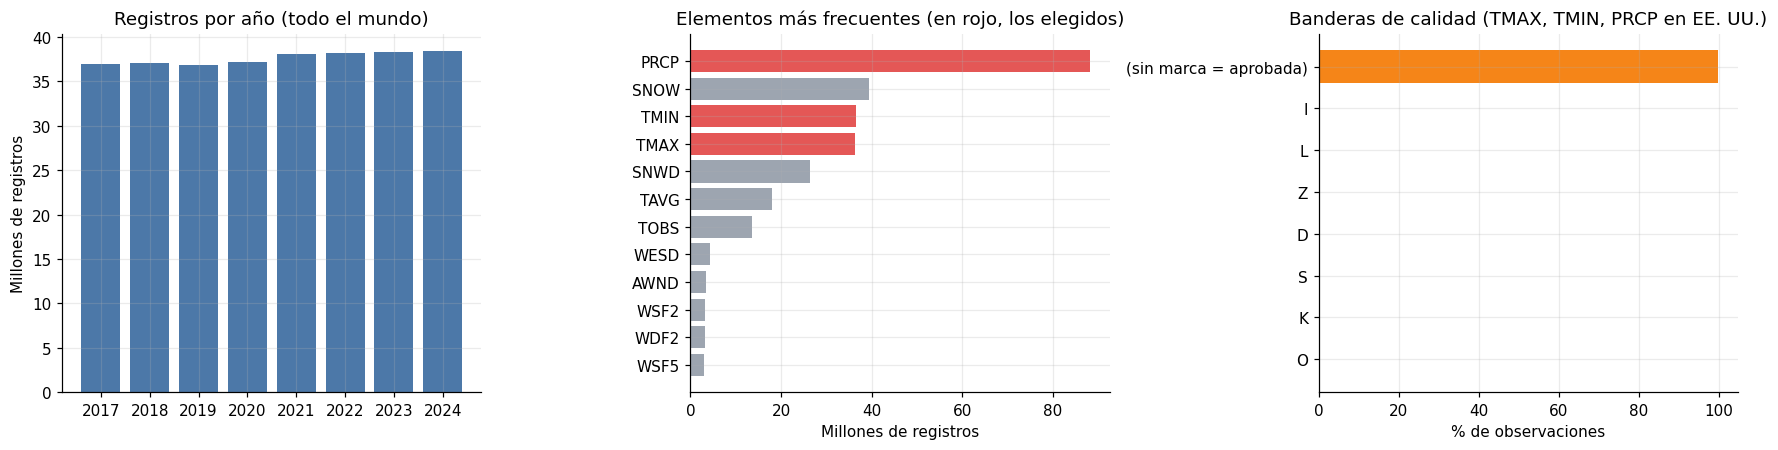

In [ ]:
CORE = ["TMAX", "TMIN", "PRCP"]
is_us = F.col("ID").startswith("US")

by_year = bronze.groupBy("year").count().orderBy("year").toPandas()
top_elements = bronze.groupBy("ELEMENT").count().orderBy(F.desc("count")).limit(12).toPandas()
us_share = bronze.agg(F.avg(is_us.cast("double"))).first()[0]
n_stations_total = bronze.agg(F.approx_count_distinct("ID")).first()[0]
n_stations_us = bronze.filter(is_us).agg(F.approx_count_distinct("ID")).first()[0]

print(f"Proporción de registros de Estados Unidos: {us_share:.1%}")
print(f"Estaciones distintas (aprox.): {n_stations_total:,} en total, {n_stations_us:,} en Estados Unidos")

core_us = bronze.filter(is_us & F.col("ELEMENT").isin(CORE))
flags = core_us.groupBy("Q_FLAG").count().toPandas()
flags["Q_FLAG"] = flags["Q_FLAG"].fillna("(sin marca = aprobada)")
flags["porcentaje"] = 100 * flags["count"] / flags["count"].sum()
display(flags.sort_values("count", ascending=False))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].bar(by_year["year"].astype(str), by_year["count"] / 1e6, color="#4C78A8")
axes[0].set(title="Registros por año (todo el mundo)", ylabel="Millones de registros")
colors = ["#E45756" if e in CORE else "#9DA5B0" for e in top_elements["ELEMENT"]]
axes[1].barh(top_elements["ELEMENT"][::-1], top_elements["count"][::-1] / 1e6, color=colors[::-1])
axes[1].set(title="Elementos más frecuentes (en rojo, los elegidos)", xlabel="Millones de registros")
f = flags.sort_values("count", ascending=False).head(8)
axes[2].barh(f["Q_FLAG"][::-1], f["porcentaje"][::-1], color="#F58518")
axes[2].set(title="Banderas de calidad (TMAX, TMIN, PRCP en EE. UU.)", xlabel="% de observaciones")
plt.tight_layout()
plt.show()

**Lectura y decisiones que se desprenden**

- **Variables base: `TMAX`, `TMIN` y `PRCP`.** Están entre los elementos más frecuentes del conjunto y son de las que se miden de forma más homogénea entre estaciones. Variables como nieve (`SNOW`, `SNWD`) existen solo en una parte de las estaciones y en ciertas estaciones del año; incluirlas llenaría la tabla de nulos estructurales (no aleatorios) y, en la práctica, haría depender el modelo de la temporada.
- **Solo Estados Unidos (`ID` que empieza con `US`).** Es un filtro por dominio, no por tamaño: la red estadounidense es densa y tiene un protocolo de observación homogéneo, y mezclar climas y redes de todo el mundo cambiaría la pregunta del proyecto. Además hace que los resultados del tablero sean interpretables por estado.
- **Observaciones con bandera de calidad: se excluyen.** Las banderas indican que NOAA detectó un problema (duplicado, inconsistencia, valor atípico, etc.). Elijo descartarlas en lugar de intentar corregirlas porque no tengo un criterio meteorológico propio mejor que el de las pruebas oficiales; la gráfica anterior muestra qué proporción de las observaciones se pierde por este motivo.

## 5. Limpieza e ingeniería de variables (capas plata y oro)

### 5.1 Capa plata: una fila por estación y día

**Decisiones**

- **Reestructurar de formato largo a ancho con agregación condicional** (`MAX(CASE WHEN ELEMENT = ...)`) en lugar de `pivot()`. Ambas producen el mismo resultado, pero la agregación condicional no necesita que Spark primero descubra los valores distintos de `ELEMENT`, y es más explícita en cuanto a qué hago con duplicados (se queda un valor por estación, día y elemento).
- **Convertir unidades**: las décimas de °C y de mm se dividen entre 10 para trabajar en °C y mm.
- **Exigir `TMAX` y `TMIN`** en cada fila. `TMAX` es la base de la variable de respuesta y `TMIN` aporta el rango térmico del día. Una fila sin alguno de los dos no sirve para este problema.
- **`PRCP` es opcional.** Muchas estaciones miden temperatura pero no precipitación en todos los días. Eliminar esas filas reduciría mucho los datos y sesgaría la muestra hacia estaciones con instrumentación completa. En su lugar creo una **bandera `prcp_missing`** y dejo que el `Imputer` del pipeline use la mediana; así el modelo puede distinguir "no llovió" de "no sé si llovió".
- **Límites físicos.** Descarto temperaturas fuera de rangos plausibles para el territorio estadounidense (`TMAX` entre −50 y 55 °C, `TMIN` entre −60 y 50 °C), casos con `TMAX < TMIN` y precipitaciones negativas o mayores a 500 mm en un día. Son controles contra errores de captura que las banderas de NOAA podrían no haber detectado.
- **Unir con el catálogo de estaciones** (latitud, longitud, elevación, estado, nombre). Es una tabla pequeña, así que la envío a todos los nodos con `broadcast` para evitar un *shuffle* de la tabla grande.
- **Escribir la capa plata en Parquet.** Con ello las ventanas y el tablero parten de datos ya limpios y no repiten la limpieza.

In [ ]:
# 5.1 Catálogo de estaciones (archivo de ancho fijo) y capa plata
stations = (
    spark.read.text(str(stations_path))
    .select(
        F.trim(F.substring("value", 1, 11)).alias("station_id"),
        F.trim(F.substring("value", 13, 8)).cast("double").alias("lat"),
        F.trim(F.substring("value", 22, 9)).cast("double").alias("lon"),
        F.trim(F.substring("value", 32, 6)).cast("double").alias("elev"),
        F.trim(F.substring("value", 39, 2)).alias("state"),
        F.trim(F.substring("value", 42, 30)).alias("name"),
    )
    .filter(F.col("station_id").startswith("US"))
    .filter(F.col("lat").isNotNull() & F.col("lon").isNotNull())
    .withColumn("elev", F.when(F.col("elev") > -999, F.col("elev")))   # -999.9 = sin dato
)

# Embudo de filtros (todas son transformaciones perezosas)
core_obs = bronze.filter(is_us & F.col("ELEMENT").isin(CORE))
clean_obs = core_obs.filter(F.col("Q_FLAG").isNull() | (F.trim(F.col("Q_FLAG")) == ""))

if built(SILVER):
    print("La capa plata ya existe; se reutiliza.")
else:
    t0 = time.perf_counter()
    daily = (
        clean_obs.groupBy("ID", "DATE")
        .agg(
            F.max(F.when(F.col("ELEMENT") == "TMAX", F.col("DATA_VALUE"))).alias("tmax_raw"),
            F.max(F.when(F.col("ELEMENT") == "TMIN", F.col("DATA_VALUE"))).alias("tmin_raw"),
            F.max(F.when(F.col("ELEMENT") == "PRCP", F.col("DATA_VALUE"))).alias("prcp_raw"),
        )
        .withColumnRenamed("ID", "station_id")
        .withColumn("date", F.to_date(F.col("DATE").cast("string"), "yyyyMMdd"))
        .withColumn("tmax", F.col("tmax_raw") / 10.0)
        .withColumn("tmin", F.col("tmin_raw") / 10.0)
        .withColumn("prcp", F.col("prcp_raw") / 10.0)
        .filter(F.col("date").isNotNull() & F.col("tmax").isNotNull() & F.col("tmin").isNotNull())
        .filter(F.col("tmax").between(-50, 55) & F.col("tmin").between(-60, 50))
        .filter(F.col("tmax") >= F.col("tmin"))
        .filter(F.col("prcp").isNull() | F.col("prcp").between(0, 500))
        .withColumn("year", F.year("date"))
        .withColumn("month", F.month("date"))
        .withColumn("day_num", F.datediff(F.col("date"), F.lit("1970-01-01").cast("date")))
        .join(F.broadcast(stations), "station_id", "inner")
        .select("station_id", "name", "state", "lat", "lon", "elev",
                "date", "year", "month", "day_num", "tmax", "tmin", "prcp")
    )
    daily.write.mode("overwrite").partitionBy("year").parquet(str(SILVER))
    print(f"Capa plata escrita en {(time.perf_counter() - t0)/60:.1f} min")

silver = spark.read.parquet(str(SILVER))
n_core = core_obs.count()
n_clean_obs = clean_obs.count()
n_silver = silver.count()

funnel = pd.DataFrame({
    "etapa": ["Registros en bronce (todo el mundo, todos los elementos)",
              "Estados Unidos, elementos TMAX/TMIN/PRCP",
              "… sin bandera de calidad",
              "Estaciones-día válidos (TMAX y TMIN presentes, rangos físicos)"],
    "registros": [n_bronze, n_core, n_clean_obs, n_silver],
})
funnel["% de bronce"] = 100 * funnel["registros"] / n_bronze
display(funnel.style.format({"registros": "{:,.0f}", "% de bronce": "{:.1f}"}))

Capa plata escrita en 6.3 min


,etapa,registros,% de bronce
0,"Registros en bronce (todo el mundo, todos los elementos)","301,099,069",100.0
1,"Estados Unidos, elementos TMAX/TMIN/PRCP","104,561,021",34.7
2,… sin bandera de calidad,"104,435,783",34.7
3,"Estaciones-día válidos (TMAX y TMIN presentes, rangos físicos)","21,757,659",7.2


### 5.2 Capa oro: variables para predecir el día siguiente

La capa oro agrega a cada estación-día la información necesaria para predecir `TMAX` de **mañana**.

**Variable de respuesta (`label`)**: la `TMAX` del día siguiente. Para obtenerla uso `lead()` sobre una ventana por estación ordenada por fecha. **Solo la acepto si el día siguiente es realmente consecutivo**: las estaciones tienen huecos, y tomar "la siguiente fila" sin verificar la fecha convertiría un pronóstico a 1 día en uno a 5 o 10 días sin avisar.

**Variables predictoras y su razón de ser**

| Variable | Qué representa | Por qué la incluyo |
|----------|----------------|--------------------|
| `tmax`, `tmin`, `dtr` (= `tmax` − `tmin`) | Estado térmico de hoy y rango diurno | Es el punto de partida del pronóstico. El rango diurno es una señal de cielo despejado frente a nublado. |
| `prcp`, `prcp_missing` | Lluvia de hoy y bandera de dato faltante | Un día lluvioso suele implicar nubosidad y temperaturas máximas más bajas. La bandera evita confundir "sin dato" con "0 mm". |
| `tmax_lag1` | `TMAX` de ayer (solo si ayer es consecutivo) | Captura la tendencia: si hoy es más cálido que ayer, el sistema podría estar entrando. |
| `tmax_mean7`, `tmin_mean7` | Promedio móvil de 7 días (ventana por rango de fechas, incluye hoy) | Resume el régimen reciente y suaviza el ruido de un solo día. |
| `lat`, `lon`, `elev` | Ubicación y altitud de la estación | El clima depende de la geografía; esto permite un solo modelo para todo el país en lugar de uno por estación. |
| `doy_sin`, `doy_cos` | Día del año codificado como seno y coseno | La estacionalidad es **cíclica**: el 31 de diciembre y el 1 de enero son vecinos, pero con el número de día (365 y 1) un modelo los vería lejanos. |

**Variables que decidí no usar**

- **`station_id` como predictor.** Tiene miles de categorías y permitiría al modelo memorizar estaciones en lugar de aprender relaciones generales; la ubicación (`lat`, `lon`, `elev`) ya captura lo útil de la estación.
- **El año.** Los años de prueba están fuera del rango de entrenamiento; una variable así obligaría al modelo a extrapolar.
- **El estado.** Es una división administrativa, no climática; la latitud, la longitud y la elevación explican mejor las diferencias.

**Prevención de fuga de información.** Todas las variables usan información disponible **hasta hoy**. El promedio móvil usa la ventana `[hoy − 6, hoy]`, nunca valores posteriores. Solo `label` mira hacia adelante, y no entra como predictor.

**Calidad de la ventana.** Conservo una fila solo si existe `tmax_lag1`, existe el valor de mañana y el promedio móvil se calculó con al menos 5 de los 7 días. Prefiero perder filas a rellenar con valores inventados: el objetivo es aprender relaciones reales, no relaciones producidas por la imputación.

In [ ]:
# 5.2 Capa oro: ventanas por estación y variables del modelo
FEATURES = [
    "tmax", "tmin", "dtr", "prcp", "prcp_missing",
    "tmax_lag1", "tmax_mean7", "tmin_mean7",
    "lat", "lon", "elev", "doy_sin", "doy_cos",
]

if built(GOLD):
    print("La capa oro ya existe; se reutiliza.")
else:
    t0 = time.perf_counter()
    w = Window.partitionBy("station_id").orderBy("day_num")
    w7 = w.rangeBetween(-6, 0)       # hoy y los 6 días calendario anteriores

    g = (
        silver
        .withColumn("tmax_prev",  F.lag("tmax", 1).over(w))
        .withColumn("day_prev",   F.lag("day_num", 1).over(w))
        .withColumn("tmax_next",  F.lead("tmax", 1).over(w))
        .withColumn("day_next",   F.lead("day_num", 1).over(w))
        .withColumn("tmax_mean7", F.avg("tmax").over(w7))
        .withColumn("tmin_mean7", F.avg("tmin").over(w7))
        .withColumn("n7",         F.count("tmax").over(w7))
        # solo se aceptan vecinos realmente consecutivos
        .withColumn("tmax_lag1", F.when(F.col("day_prev") == F.col("day_num") - 1, F.col("tmax_prev")))
        .withColumn("label",     F.when(F.col("day_next") == F.col("day_num") + 1, F.col("tmax_next")))
    )

    gold_out = (
        g.filter(F.col("label").isNotNull() & F.col("tmax_lag1").isNotNull() & (F.col("n7") >= 5))
        .withColumn("dtr", F.col("tmax") - F.col("tmin"))
        .withColumn("prcp_missing", F.col("prcp").isNull().cast("double"))
        .withColumn("doy", F.dayofyear("date"))
        .withColumn("doy_sin", F.sin(2 * math.pi * F.col("doy") / 365.25))
        .withColumn("doy_cos", F.cos(2 * math.pi * F.col("doy") / 365.25))
        .select("station_id", "name", "state", "date", "year", "month", *FEATURES, "label")
    )
    gold_out.write.mode("overwrite").partitionBy("year").parquet(str(GOLD))
    print(f"Capa oro escrita en {(time.perf_counter() - t0)/60:.1f} min")

gold = spark.read.parquet(str(GOLD))
n_gold = gold.count()
print(f"Estaciones-día con variables completas para el modelo: {n_gold:,} "
      f"({n_gold / n_silver:.1%} de la capa plata)")
gold.select("station_id", "date", *FEATURES, "label").show(5, truncate=False)

Capa oro escrita en 3.9 min
Estaciones-día con variables completas para el modelo: 21,027,371 (96.6% de la capa plata)
+-----------+----------+----+----+------------------+----+------------+---------+------------------+-----------------+-----+--------+-----+--------------------+------------------+-----+
|station_id |date      |tmax|tmin|dtr               |prcp|prcp_missing|tmax_lag1|tmax_mean7        |tmin_mean7       |lat  |lon     |elev |doy_sin             |doy_cos           |label|
+-----------+----------+----+----+------------------+----+------------+---------+------------------+-----------------+-----+--------+-----+--------------------+------------------+-----+
|USC00011490|2019-01-01|22.8|12.2|10.600000000000001|11.2|0.0         |12.8     |15.0              |4.885714285714286|34.15|-85.6847|184.1|0.017201575418260506|0.9998520419557735|16.1 |
|USC00011490|2019-01-02|16.1|7.2 |8.900000000000002 |0.0 |0.0         |22.8     |15.87142857142857 |6.157142857142858|34.15|-85.6847|184.

## 6. Análisis exploratorio

El análisis se calcula con agregaciones de Spark sobre toda la capa correspondiente. Solo se convierte a pandas el resultado agregado o una muestra pequeña para graficar. Busco responder tres preguntas que afectan las decisiones de modelado:

1. ¿Qué tan fuerte es la señal de "persistencia" y qué tan fuerte la estacionalidad? Define cuánto margen hay para mejorar.
2. ¿Cómo se relacionan la geografía y la temperatura? Justifica `lat` y `elev`.
3. ¿La variable de respuesta tiene valores extremos o una distribución que complique el modelo?

Correlación TMAX hoy vs TMAX mañana:        0.938
Correlación media móvil 7 d vs TMAX mañana: 0.911


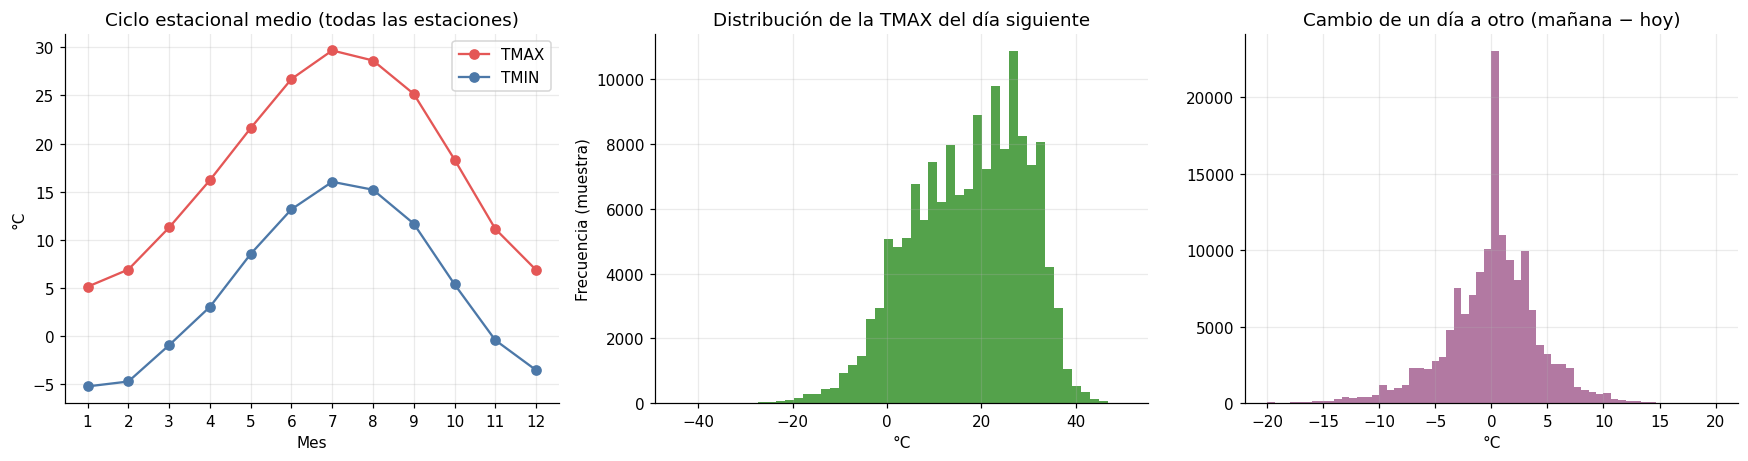

Desviación estándar del cambio diario: 4.24 °C (es el error típico de la persistencia)


In [ ]:
# 6.1 Persistencia, estacionalidad y distribución de la variable de respuesta
corr_persist = gold.stat.corr("tmax", "label")
corr_mean7   = gold.stat.corr("tmax_mean7", "label")
print(f"Correlación TMAX hoy vs TMAX mañana:        {corr_persist:.3f}")
print(f"Correlación media móvil 7 d vs TMAX mañana: {corr_mean7:.3f}")

monthly = (silver.groupBy("month")
           .agg(F.avg("tmax").alias("tmax_media"), F.avg("tmin").alias("tmin_media"),
                F.stddev("tmax").alias("tmax_desv"))
           .orderBy("month").toPandas())

frac = min(1.0, 150_000 / n_gold)
eda = gold.select("tmax", "label", "lat", "elev").sample(False, frac, seed=SEED).toPandas()
eda["cambio_diario"] = eda["label"] - eda["tmax"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
axes[0].plot(monthly["month"], monthly["tmax_media"], marker="o", color="#E45756", label="TMAX")
axes[0].plot(monthly["month"], monthly["tmin_media"], marker="o", color="#4C78A8", label="TMIN")
axes[0].set(title="Ciclo estacional medio (todas las estaciones)", xlabel="Mes", ylabel="°C")
axes[0].set_xticks(range(1, 13)); axes[0].legend()
axes[1].hist(eda["label"], bins=50, color="#54A24B")
axes[1].set(title="Distribución de la TMAX del día siguiente", xlabel="°C", ylabel="Frecuencia (muestra)")
axes[2].hist(eda["cambio_diario"], bins=60, range=(-20, 20), color="#B279A2")
axes[2].set(title="Cambio de un día a otro (mañana − hoy)", xlabel="°C")
plt.tight_layout(); plt.show()

print(f"Desviación estándar del cambio diario: {eda['cambio_diario'].std():.2f} °C "
      f"(es el error típico de la persistencia)")

Estaciones con al menos un año de datos: 8,448


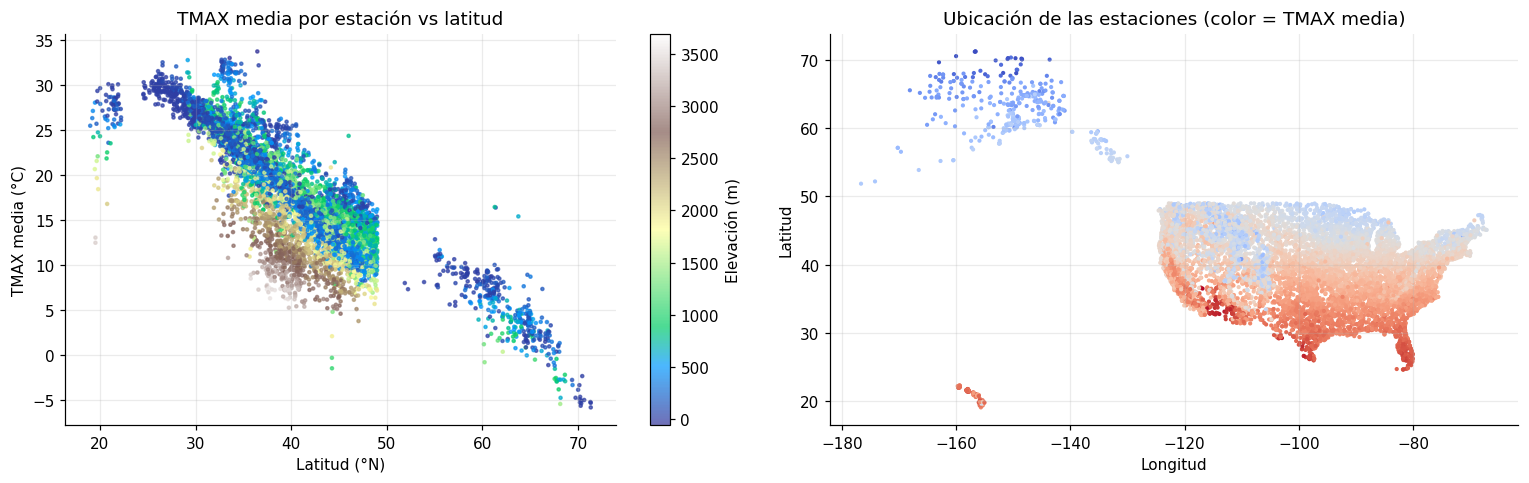

In [ ]:
# 6.2 Geografía: promedio por estación frente a latitud y elevación
station_stats = (
    silver.groupBy("station_id", "lat", "lon", "elev")
    .agg(F.count("*").alias("dias"), F.avg("tmax").alias("tmax_media"))
    .filter(F.col("dias") >= 365)
    .toPandas()
)
print(f"Estaciones con al menos un año de datos: {len(station_stats):,}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sc = axes[0].scatter(station_stats["lat"], station_stats["tmax_media"], c=station_stats["elev"],
                     s=4, cmap="terrain", alpha=0.7)
axes[0].set(title="TMAX media por estación vs latitud", xlabel="Latitud (°N)", ylabel="TMAX media (°C)")
fig.colorbar(sc, ax=axes[0], label="Elevación (m)")
axes[1].scatter(station_stats["lon"], station_stats["lat"], c=station_stats["tmax_media"],
                s=3, cmap="coolwarm")
axes[1].set(title="Ubicación de las estaciones (color = TMAX media)", xlabel="Longitud", ylabel="Latitud")
plt.tight_layout(); plt.show()

**Qué concluyo de la exploración y cómo afecta al modelo** (lo que se espera ver y que conviene contrastar con las gráficas al ejecutar el notebook)

- **La persistencia ya explica mucho**, porque el clima de hoy se parece al de mañana. Esto confirma que la referencia a vencer es exigente y que el margen de mejora está en lo que *no* captura la persistencia: tendencias recientes, geografía y la fase de la estación.
- **La estacionalidad domina la varianza total.** Esto tiene una consecuencia importante para evaluar: el R² será alto casi de forma automática, porque predecir "invierno frío, verano cálido" ya explica gran parte de la variación. Por eso baso la comparación en el **RMSE y el MAE frente a la persistencia**, y uso el R² solo como complemento.
- **La latitud y la elevación se relacionan claramente con la temperatura media**, lo que respalda usar `lat`, `lon` y `elev` en lugar del identificador de estación.
- **La distribución del cambio diario tiene colas** (frentes fríos, olas de calor). Esto anticipa que los modelos basados en árboles, que no suponen una relación lineal ni normalidad, pueden aprovechar mejor estas situaciones que una regresión lineal.

## 7. Diseño experimental: partición temporal y muestra de entrenamiento

### Partición por años, no aleatoria

En datos meteorológicos, los días consecutivos de una misma estación son casi copias unos de otros. Si dividiera las filas al azar (por ejemplo 80/20), el conjunto de prueba tendría días pegados a días de entrenamiento de la misma estación y el modelo parecería mejor de lo que realmente es. Además, el uso real de un pronóstico es predecir **el futuro**.

Por eso divido por **años completos**:

| Conjunto | Años | Uso |
|----------|------|-----|
| Entrenamiento | 2017–2022 | Ajustar los modelos |
| Validación | 2023 | Comparar algoritmos y elegir hiperparámetros |
| Prueba | 2024 | Evaluación final, una sola vez, con el año completo |

Cada año completo contiene las cuatro estaciones, de modo que ningún conjunto queda sesgado hacia una época. Una limitación menor: la fila del 31 de diciembre de 2022 tiene como objetivo el 1 de enero de 2023; es un solo día por estación y lo dejo documentado en lugar de complicar la partición.

### Muestra de entrenamiento

- **El procesamiento usa toda la base; el entrenamiento usa una muestra de filas.** Los modelos de árboles en MLlib en una sola máquina con 2 núcleos tardarían demasiado con decenas de millones de filas, y entrenar más filas de la misma estación y día cercano aporta poca información nueva. Tomo una muestra aleatoria simple del conjunto de entrenamiento y otra del de validación.
- **La evaluación final sí se hace con el año de prueba completo**, porque solo requiere aplicar el modelo (una operación distribuida y barata), no entrenarlo. Así la métrica final no depende de una muestra.
- **No balanceo ni estratifico**: es regresión y la variable de respuesta es continua; una muestra aleatoria simple conserva la distribución real (incluida la estacionalidad).
- Los tamaños de muestra son parámetros (`TRAIN_ROWS`, `VAL_ROWS`) y pueden aumentarse si se dispone de más recursos.

In [ ]:
# 7.1 Partición temporal y muestras
TRAIN_END_YEAR = 2022
VAL_YEAR = 2023
TEST_YEAR = 2024
TRAIN_ROWS = 600_000      # filas aproximadas para entrenar
VAL_ROWS = 250_000        # filas aproximadas para validar

years_available = sorted(r["year"] for r in gold.select("year").distinct().collect())
print("Años disponibles en la capa oro:", years_available)
assert VAL_YEAR in years_available and TEST_YEAR in years_available, "Faltan años de validación o prueba."

pool = gold.filter(F.col("year") <= TRAIN_END_YEAR)
val_pool = gold.filter(F.col("year") == VAL_YEAR)
n_pool, n_val_pool = pool.count(), val_pool.count()

train = pool.sample(False, min(1.0, TRAIN_ROWS / n_pool), seed=SEED).cache()
val = val_pool.sample(False, min(1.0, VAL_ROWS / n_val_pool), seed=SEED).cache()
test = gold.filter(F.col("year") == TEST_YEAR).persist(StorageLevel.DISK_ONLY)

split_table = pd.DataFrame({
    "conjunto": ["Entrenamiento (muestra)", "Validación (muestra)", "Prueba (año completo)"],
    "años": [f"{min(years_available)}–{TRAIN_END_YEAR}", str(VAL_YEAR), str(TEST_YEAR)],
    "filas disponibles": [n_pool, n_val_pool, test.count()],
    "filas usadas": [train.count(), val.count(), test.count()],
})
display(split_table.style.format({"filas disponibles": "{:,}", "filas usadas": "{:,}"}))

# Verificación de que la distribución de la variable de respuesta es comparable entre conjuntos
dist = pd.DataFrame({
    "conjunto": ["Entrenamiento", "Validación", "Prueba"],
    "label_media": [train.agg(F.avg("label")).first()[0], val.agg(F.avg("label")).first()[0], test.agg(F.avg("label")).first()[0]],
    "label_desv": [train.agg(F.stddev("label")).first()[0], val.agg(F.stddev("label")).first()[0], test.agg(F.stddev("label")).first()[0]],
})
display(dist.style.format({"label_media": "{:.2f}", "label_desv": "{:.2f}"}))

Años disponibles en la capa oro: [2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]


,conjunto,años,filas disponibles,filas usadas
0,Entrenamiento (muestra),2017–2022,"15,944,855","599,871"
1,Validación (muestra),2023,"2,559,882","249,787"
2,Prueba (año completo),2024,"2,522,634","2,522,634"


,conjunto,label_media,label_desv
0,Entrenamiento,17.27,12.06
1,Validación,17.30,11.79
2,Prueba,17.97,11.79


## 8. Modelado con MLlib

### 8.1 Referencias para comparar (líneas base)

Antes de entrenar nada calculo dos predictores triviales en la validación:

- **Persistencia**: mañana = hoy (`tmax`).
- **Promedio de 7 días**: mañana = `tmax_mean7`.

Cualquier modelo que no mejore a estas referencias no justifica su complejidad. Son, además, la forma de interpretar el RMSE en grados: un RMSE de 3 °C significa algo distinto si la persistencia tiene 4 °C o 8 °C.

### 8.2 Algoritmos comparados y por qué

| Algoritmo | Razón de incluirlo |
|-----------|--------------------|
| **Regresión lineal** (`LinearRegression`, regularización L2) | Línea base interpretable y rápida. Si ganara, indicaría que la relación es casi lineal y no haría falta un modelo más complejo. |
| **Random Forest** (`RandomForestRegressor`) | Captura no linealidades e interacciones (por ejemplo, el efecto de la lluvia depende de la estación del año). Promedia árboles independientes, por lo que es estable y poco sensible a hiperparámetros. |
| **Gradient-Boosted Trees** (`GBTRegressor`) | Suele ser el más preciso en datos tabulares porque cada árbol corrige los errores del anterior. A cambio es más lento (se entrena de forma secuencial) y más propenso a sobreajustar. |

No incluyo redes neuronales ni modelos de series de tiempo especializados: MLlib no ofrece redes profundas para regresión tabular de este tipo y el objetivo del trabajo es el flujo completo de Big Data con las herramientas de Spark.

### 8.3 Pipeline

Todo el preprocesamiento va dentro de un `Pipeline` para que se aplique **exactamente igual** al entrenar, validar, probar y predecir con datos nuevos:

1. `Imputer` (mediana): rellena los nulos de `prcp` y `elev`. Uso la mediana porque `prcp` está muy sesgada (muchos ceros y pocos valores muy altos) y la media daría un valor poco representativo. La mediana se calcula **solo con los datos de entrenamiento** y se reutiliza después.
2. `VectorAssembler`: junta las variables en un solo vector.
3. `StandardScaler`: **solo para la regresión lineal**. Los árboles dividen por umbrales y no cambian con la escala; en cambio, la regularización de la regresión lineal sí penaliza distinto a variables con escalas distintas.
4. El estimador.

### 8.4 Métricas

- **RMSE** (°C): penaliza más los errores grandes; es la métrica principal para comparar y está en las mismas unidades que la temperatura.
- **MAE** (°C): error absoluto típico, más fácil de explicar y menos sensible a casos extremos.
- **R²**: se reporta, pero con la advertencia de la sección 6 (la estacionalidad lo infla).

### 8.5 Selección de hiperparámetros

Con la partición temporal, **no uso validación cruzada aleatoria**: mezclaría días vecinos entre entrenamiento y validación y daría un error optimista. En su lugar comparo candidatos en el **año de validación** (2023). Primero comparo los tres algoritmos con una configuración razonable; luego afino solo el ganador con una cuadrícula pequeña. Afinar los tres consumiría mucho tiempo de cómputo y casi todo sería trabajo sobre modelos que ya perdieron.

### 8.6 Reajuste final

Con el mejor algoritmo y los mejores hiperparámetros, **vuelvo a entrenar con entrenamiento + validación** antes de evaluar en 2024. El año de validación es el más cercano al de prueba y contiene información reciente que conviene aprovechar. Los hiperparámetros ya fueron elegidos, de modo que la prueba sigue sin haber influido en ninguna decisión.

In [ ]:
# 8.1 Pipeline, evaluadores y líneas base
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import Imputer, VectorAssembler, StandardScaler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator

LIN, RF, GBT = "Regresión lineal", "Random Forest", "GBT"

def build_pipeline(name, **p):
    imputed = [f"{c}_imp" for c in FEATURES]
    imputer = Imputer(inputCols=FEATURES, outputCols=imputed, strategy="median")
    assembler = VectorAssembler(inputCols=imputed, outputCol="features_raw", handleInvalid="keep")
    stages = [imputer, assembler]
    if name == LIN:
        stages.append(StandardScaler(inputCol="features_raw", outputCol="features", withMean=True, withStd=True))
        est = LinearRegression(featuresCol="features", labelCol="label", maxIter=100,
                               regParam=p.get("regParam", 0.01), elasticNetParam=0.0, standardization=False)
    elif name == RF:
        est = RandomForestRegressor(featuresCol="features_raw", labelCol="label",
                                    numTrees=p.get("numTrees", 40), maxDepth=p.get("maxDepth", 8),
                                    maxBins=64, seed=SEED)
    elif name == GBT:
        est = GBTRegressor(featuresCol="features_raw", labelCol="label",
                           maxIter=p.get("maxIter", 40), maxDepth=p.get("maxDepth", 5),
                           stepSize=0.1, maxBins=64, seed=SEED)
    else:
        raise ValueError(name)
    stages.append(est)
    return Pipeline(stages=stages)

evaluators = {m: RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName=m)
              for m in ("rmse", "mae", "r2")}

def score(df):
    return {m: float(ev.evaluate(df)) for m, ev in evaluators.items()}

base_val = {
    "Persistencia (mañana = hoy)": score(val.withColumn("prediction", F.col("tmax"))),
    "Promedio móvil de 7 días":    score(val.withColumn("prediction", F.col("tmax_mean7"))),
}
display(pd.DataFrame(base_val).T.style.format("{:.3f}"))

,rmse,mae,r2
Persistencia (mañana = hoy),3.993,2.908,0.885
Promedio móvil de 7 días,4.815,3.688,0.833


Regresión lineal: entrenado en 24 s
Random Forest: entrenado en 98 s
GBT: entrenado en 109 s


,modelo,parametros,rmse,mae,r2,seg_entrenamiento
0,Regresión lineal,{'regParam': 0.01},3.673,2.787,0.9029,24
1,Random Forest,"{'numTrees': 40, 'maxDepth': 8}",3.701,2.795,0.9014,98
2,GBT,"{'maxIter': 40, 'maxDepth': 5}",3.657,2.771,0.9038,109


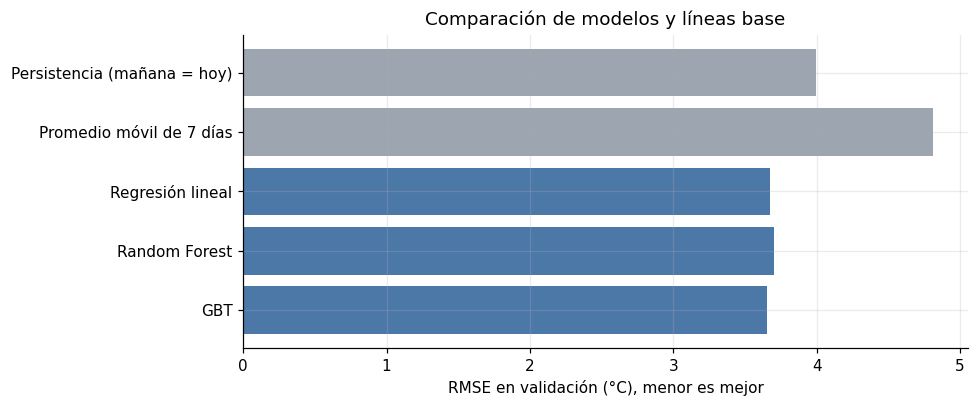

In [ ]:
# 8.2 Comparación de los tres algoritmos en el año de validación
candidates = {
    LIN: {"regParam": 0.01},
    RF:  {"numTrees": 40, "maxDepth": 8},
    GBT: {"maxIter": 40, "maxDepth": 5},
}

rows = []
for name, params in candidates.items():
    t0 = time.perf_counter()
    model = build_pipeline(name, **params).fit(train)
    secs = time.perf_counter() - t0
    rows.append({"modelo": name, "parametros": params, **score(model.transform(val)), "seg_entrenamiento": secs})
    print(f"{name}: entrenado en {secs:,.0f} s")

comparison = pd.DataFrame(rows)
display(comparison.style.format({"rmse": "{:.3f}", "mae": "{:.3f}", "r2": "{:.4f}", "seg_entrenamiento": "{:.0f}"}))

labels = list(base_val.keys()) + comparison["modelo"].tolist()
rmses = [v["rmse"] for v in base_val.values()] + comparison["rmse"].tolist()
plt.figure(figsize=(9, 3.8))
bars = plt.barh(labels[::-1], rmses[::-1], color=["#4C78A8"] * len(comparison) + ["#9DA5B0"] * len(base_val))
plt.xlabel("RMSE en validación (°C), menor es mejor")
plt.title("Comparación de modelos y líneas base")
plt.tight_layout(); plt.show()

In [ ]:
# 8.3 Afinación del algoritmo ganador (cuadrícula pequeña, evaluada en validación)
best_name = comparison.sort_values("rmse").iloc[0]["modelo"]
print("Algoritmo con menor RMSE en validación:", best_name)

GRIDS = {
    LIN: [{"regParam": r} for r in (0.0, 0.01, 0.1)],
    RF:  [{"numTrees": n, "maxDepth": d} for d in (6, 10) for n in (30, 60)],
    GBT: [{"maxIter": n, "maxDepth": d} for d in (4, 6) for n in (30, 60)],
}

tuning_rows = [{"parametros": candidates[best_name],
                **comparison.set_index("modelo").loc[best_name, ["rmse", "mae", "r2"]].to_dict()}]
for params in GRIDS[best_name]:
    if params == candidates[best_name]:
        continue
    t0 = time.perf_counter()
    m = build_pipeline(best_name, **params).fit(train)
    sc = score(m.transform(val))
    tuning_rows.append({"parametros": params, **sc})
    print(f"{params} -> RMSE {sc['rmse']:.3f} ({time.perf_counter()-t0:,.0f} s)")

tuning = pd.DataFrame(tuning_rows).sort_values("rmse").reset_index(drop=True)
display(tuning.style.format({"rmse": "{:.3f}", "mae": "{:.3f}", "r2": "{:.4f}"}))
best_params = tuning.loc[0, "parametros"]
print("Mejor configuración:", best_name, best_params)

Algoritmo con menor RMSE en validación: GBT
{'maxIter': 30, 'maxDepth': 4} -> RMSE 3.758 (69 s)
{'maxIter': 60, 'maxDepth': 4} -> RMSE 3.669 (131 s)
{'maxIter': 30, 'maxDepth': 6} -> RMSE 3.643 (106 s)
{'maxIter': 60, 'maxDepth': 6} -> RMSE 3.609 (194 s)


,parametros,rmse,mae,r2
0,"{'maxIter': 60, 'maxDepth': 6}",3.609,2.734,0.9063
1,"{'maxIter': 30, 'maxDepth': 6}",3.643,2.760,0.9045
2,"{'maxIter': 40, 'maxDepth': 5}",3.657,2.771,0.9038
3,"{'maxIter': 60, 'maxDepth': 4}",3.669,2.780,0.9031
4,"{'maxIter': 30, 'maxDepth': 4}",3.758,2.848,0.8984


Mejor configuración: GBT {'maxIter': 60, 'maxDepth': 6}


In [ ]:
# 8.4 Reajuste final con entrenamiento + validación
train_final = train.unionByName(val)
t0 = time.perf_counter()
final_model = build_pipeline(best_name, **best_params).fit(train_final)
print(f"Modelo final ({best_name}, {best_params}) entrenado en {time.perf_counter() - t0:,.0f} s "
      f"con {train_final.count():,} filas")

Modelo final (GBT, {'maxIter': 60, 'maxDepth': 6}) entrenado en 246 s con 849,658 filas


## 9. Evaluación final en el año de prueba

Aplico el modelo final al **año de prueba completo** (2024) y calculo las métricas con `RegressionEvaluator`. Para dar contexto, calculo en el mismo conjunto las líneas base. Después reviso **dónde** se equivoca el modelo, porque una métrica global puede ocultar que falla en una época del año o en una región:

- Gráfica de valores reales contra predichos y distribución del error.
- Error por mes, comparado con la persistencia.
- Error por estado.
- Importancia de variables, como apoyo para interpretar (no como explicación causal).

In [ ]:
# 9.1 Métricas en el año de prueba (distribuidas) frente a la persistencia
pred_test = (
    final_model.transform(test)
    .select("station_id", "name", "state", "date", "month", "tmax", "tmin", "tmax_mean7", "label", "prediction")
    .persist(StorageLevel.DISK_ONLY)
)
n_test_pred = pred_test.count()

metrics_model = score(pred_test)
metrics_persist = score(pred_test.withColumn("prediction", F.col("tmax")))
metrics_mean7 = score(pred_test.withColumn("prediction", F.col("tmax_mean7")))

metrics_df = pd.DataFrame({"Modelo final": metrics_model, "Persistencia": metrics_persist,
                           "Promedio 7 días": metrics_mean7}).T
display(metrics_df.style.format({"rmse": "{:.3f}", "mae": "{:.3f}", "r2": "{:.4f}"}))

mejora_rmse = 1 - metrics_model["rmse"] / metrics_persist["rmse"]
mejora_mae = 1 - metrics_model["mae"] / metrics_persist["mae"]
print(f"Observaciones evaluadas: {n_test_pred:,}")
print(f"Mejora del RMSE frente a la persistencia: {mejora_rmse:.1%}")
print(f"Mejora del MAE frente a la persistencia:  {mejora_mae:.1%}")

,rmse,mae,r2
Modelo final,3.642,2.748,0.9046
Persistencia,4.006,2.918,0.8846
Promedio 7 días,4.780,3.675,0.8356


Observaciones evaluadas: 2,522,634
Mejora del RMSE frente a la persistencia: 9.1%
Mejora del MAE frente a la persistencia:  5.8%


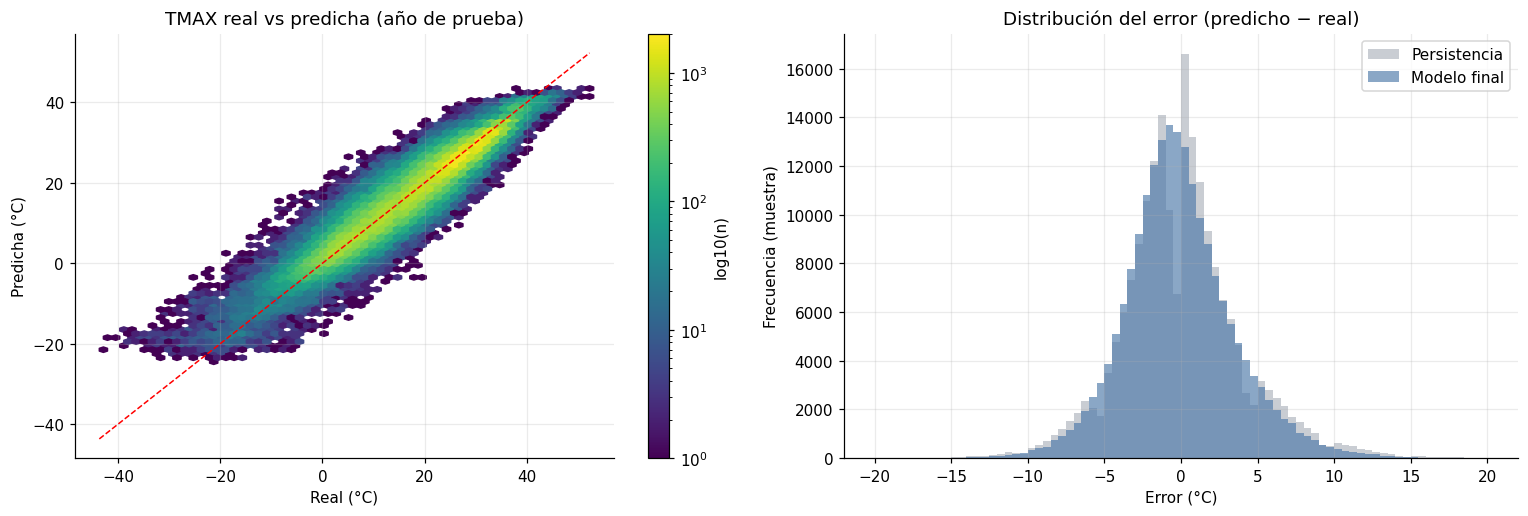

In [ ]:
# 9.2 Real vs predicho y distribución del error (muestra para graficar)
rp = (pred_test.select("label", "prediction", "tmax")
      .sample(False, min(1.0, 200_000 / n_test_pred), seed=SEED).toPandas())
rp["error_modelo"] = rp["prediction"] - rp["label"]
rp["error_persistencia"] = rp["tmax"] - rp["label"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
hb = axes[0].hexbin(rp["label"], rp["prediction"], gridsize=60, bins="log", cmap="viridis", mincnt=1)
lims = [rp["label"].min(), rp["label"].max()]
axes[0].plot(lims, lims, "r--", lw=1)
axes[0].set(title="TMAX real vs predicha (año de prueba)", xlabel="Real (°C)", ylabel="Predicha (°C)")
fig.colorbar(hb, ax=axes[0], label="log10(n)")
axes[1].hist(rp["error_persistencia"], bins=80, range=(-20, 20), alpha=0.55, label="Persistencia", color="#9DA5B0")
axes[1].hist(rp["error_modelo"], bins=80, range=(-20, 20), alpha=0.65, label="Modelo final", color="#4C78A8")
axes[1].set(title="Distribución del error (predicho − real)", xlabel="Error (°C)", ylabel="Frecuencia (muestra)")
axes[1].legend()
plt.tight_layout(); plt.show()

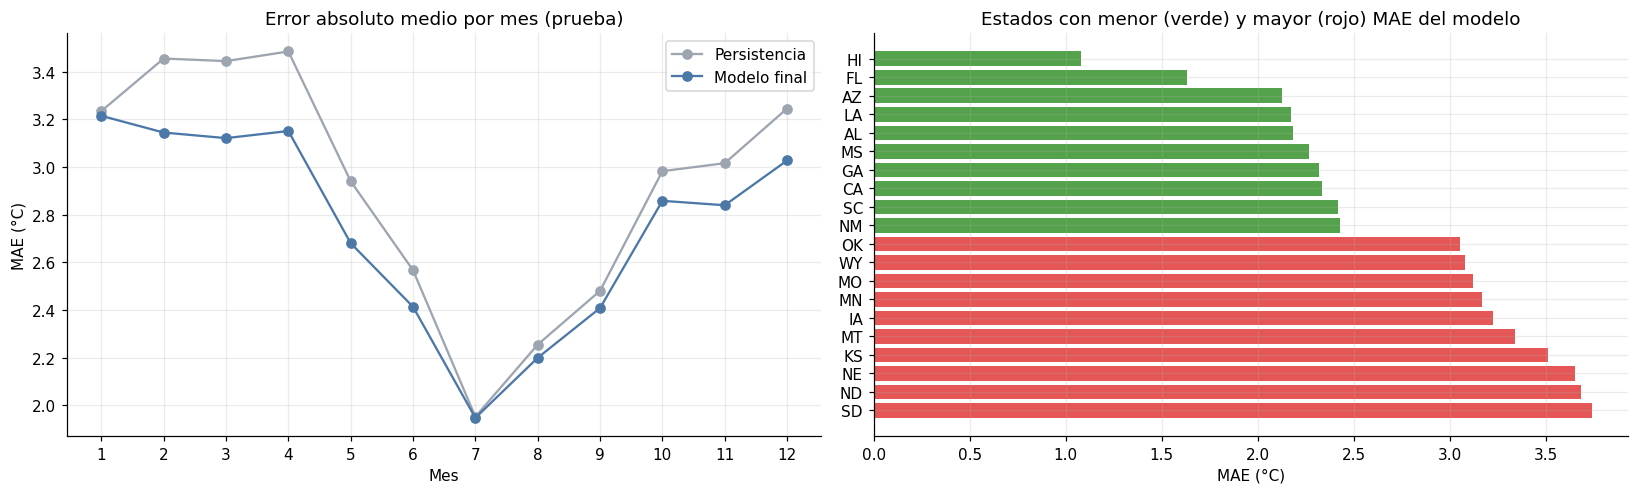

Estados donde el modelo mejora MENOS a la persistencia:


,state,n,mae_modelo,mae_persistencia,mejora_pct
25,HI,14637,1.08,1.00,-7.9
10,AK,106062,2.73,2.58,-6.0
2,AZ,69191,2.13,2.11,-0.7
27,CA,195552,2.33,2.35,0.7
24,NV,56513,2.50,2.57,2.7


In [ ]:
# 9.3 Error por mes y por estado (agregaciones distribuidas)
abs_model = F.abs(F.col("label") - F.col("prediction"))
abs_persist = F.abs(F.col("label") - F.col("tmax"))

by_month = (pred_test.groupBy("month")
            .agg(F.avg(abs_model).alias("mae_modelo"), F.avg(abs_persist).alias("mae_persistencia"),
                 F.count("*").alias("n"))
            .orderBy("month").toPandas())

by_state = (pred_test.filter(F.col("state") != "")
            .groupBy("state")
            .agg(F.avg(abs_model).alias("mae_modelo"), F.avg(abs_persist).alias("mae_persistencia"),
                 F.count("*").alias("n"))
            .filter(F.col("n") >= 5000)
            .toPandas())
by_state["mejora_pct"] = 100 * (1 - by_state["mae_modelo"] / by_state["mae_persistencia"])
by_state = by_state.sort_values("mae_modelo")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
axes[0].plot(by_month["month"], by_month["mae_persistencia"], marker="o", color="#9DA5B0", label="Persistencia")
axes[0].plot(by_month["month"], by_month["mae_modelo"], marker="o", color="#4C78A8", label="Modelo final")
axes[0].set(title="Error absoluto medio por mes (prueba)", xlabel="Mes", ylabel="MAE (°C)")
axes[0].set_xticks(range(1, 13)); axes[0].legend()
extremes = pd.concat([by_state.head(10), by_state.tail(10)])
axes[1].barh(extremes["state"], extremes["mae_modelo"],
             color=["#54A24B"] * 10 + ["#E45756"] * 10)
axes[1].set(title="Estados con menor (verde) y mayor (rojo) MAE del modelo", xlabel="MAE (°C)")
axes[1].invert_yaxis()
plt.tight_layout(); plt.show()

print("Estados donde el modelo mejora MENOS a la persistencia:")
display(by_state.sort_values("mejora_pct").head(5)[["state", "n", "mae_modelo", "mae_persistencia", "mejora_pct"]]
        .style.format({"mae_modelo": "{:.2f}", "mae_persistencia": "{:.2f}", "mejora_pct": "{:.1f}"}))

,variable,importancia
0,tmax,0.7946
1,dtr,0.0339
2,doy_cos,0.0331
3,tmax_lag1,0.0260
4,lat,0.0222
5,tmax_mean7,0.0203
6,prcp,0.0181
7,lon,0.0153
8,doy_sin,0.0149
9,elev,0.0086


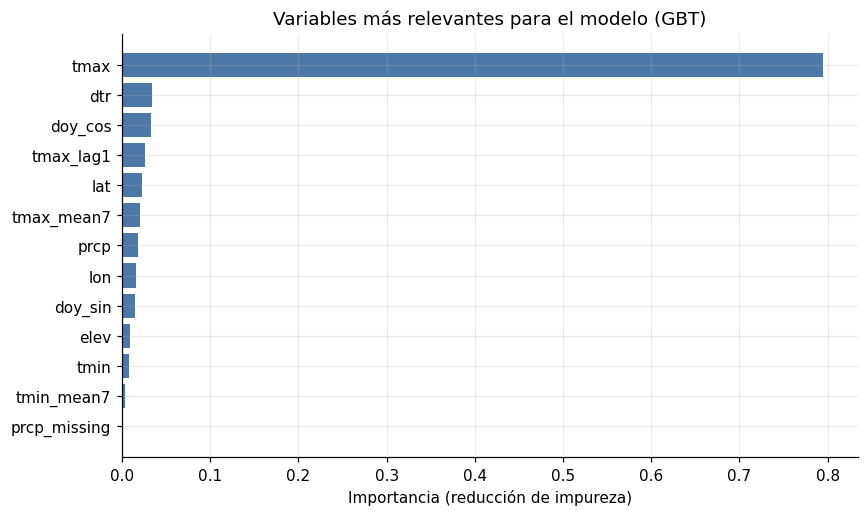

In [ ]:
# 9.4 Importancia de variables (interpretación, no causalidad)
last_stage = final_model.stages[-1]
if hasattr(last_stage, "featureImportances"):
    values = last_stage.featureImportances.toArray()
    kind = "Importancia (reducción de impureza)"
else:
    values = np.abs(last_stage.coefficients.toArray())
    kind = "|Coeficiente| con variables estandarizadas"

importance_df = (pd.DataFrame({"variable": FEATURES, "importancia": values})
                 .sort_values("importancia", ascending=False).reset_index(drop=True))
display(importance_df.style.format({"importancia": "{:.4f}"}))

plt.figure(figsize=(8, 4.8))
plt.barh(importance_df["variable"][::-1], importance_df["importancia"][::-1], color="#4C78A8")
plt.title(f"Variables más relevantes para el modelo ({best_name})")
plt.xlabel(kind)
plt.tight_layout(); plt.show()

**Cómo interpreto esta sección**

- La comparación con la persistencia es el criterio principal. Si el modelo apenas la mejora, el resultado es honesto pero modesto: significa que la información disponible (observaciones pasadas de una estación) ya está casi toda contenida en el valor de hoy.
- El **error por mes** muestra si el modelo es más útil en ciertas épocas. En el invierno y en las estaciones de transición hay más cambios bruscos por el paso de frentes, que son difíciles de anticipar sin datos de presión, viento o pronósticos numéricos, variables que este conjunto no incluye.
- El **error por estado** señala regiones donde el modelo ayuda menos. Un modelo único para todo el país puede rendir distinto en climas muy distintos (costa, montaña, desierto).
- La **importancia de variables** indica qué usa el modelo para predecir, no qué *causa* la temperatura. Variables correlacionadas entre sí (`tmax`, `tmax_lag1`, `tmax_mean7`) se reparten la importancia, así que no conviene interpretar una por una de forma aislada.

## 10. Predicciones con datos no vistos

Pruebo el modelo de tres maneras complementarias, de menos a más cercana al uso real:

1. **Filas del año de prueba (2024).** Ejemplos al azar con su valor real, la predicción del modelo y la de persistencia. Estos datos no participaron en el entrenamiento ni en la selección de hiperparámetros.
2. **Una estación completa a lo largo del año.** Muestra cómo se comporta el modelo día a día en una serie continua y si sigue bien los cambios bruscos.
3. **Escenarios nuevos construidos a mano.** Son casos hipotéticos pero plausibles (desierto en verano, norte en invierno, etc.) que pasan por el mismo `Pipeline`, incluido un caso sin dato de precipitación para comprobar que la imputación funciona con datos nuevos. **Estos escenarios son ilustrativos: no tienen un valor real contra el cual comparar**, y sirven para revisar que las predicciones sean coherentes con la meteorología (por ejemplo, que no ocurran temperaturas absurdas).

In [ ]:
# 10.1 Ejemplos al azar del año de prueba
ejemplos = (
    pred_test.orderBy(F.rand(seed=123)).limit(15)
    .select("name", "state", "date", F.round("tmax", 1).alias("tmax_hoy"),
            F.round("label", 1).alias("tmax_real_mañana"),
            F.round("prediction", 1).alias("prediccion_modelo"))
    .toPandas()
)
ejemplos["error_modelo"] = (ejemplos["prediccion_modelo"] - ejemplos["tmax_real_mañana"]).round(1)
ejemplos["error_persistencia"] = (ejemplos["tmax_hoy"] - ejemplos["tmax_real_mañana"]).round(1)
display(ejemplos)

,name,state,date,tmax_hoy,tmax_real_mañana,prediccion_modelo,error_modelo,error_persistencia
0,MILESVILLE 5 NE,SD,2024-07-13,36.7,32.8,33.6,0.8,3.9
1,GUION FARM NORTH CAROLINA,NC,2024-06-14,28.9,28.9,27.1,-1.8,0.0
2,CASPER-NATRONA CO AP,WY,2024-06-13,30.6,30.6,28.8,-1.8,0.0
3,Blue Lakes,CA,2024-05-29,15.3,17.1,14.7,-2.4,-1.8
4,MC NEAL,AZ,2024-10-19,23.3,27.2,24.1,-3.1,-3.9
5,ANDALUSIA OPP AP,AL,2024-12-03,12.2,17.2,14.0,-3.2,-5.0
6,W PT 2 NW,VA,2024-08-17,30.0,30.6,28.5,-2.1,-0.6
7,METCALF GAP CALIFORNIA,CA,2024-07-02,38.9,39.4,37.2,-2.2,-0.5
8,Bisson Creek,MT,2024-05-20,11.8,13.7,15.0,1.3,-1.9
9,CINCINNATI MUNI AP LUNKEN FLD,OH,2024-04-20,15.0,12.2,18.1,5.9,2.8


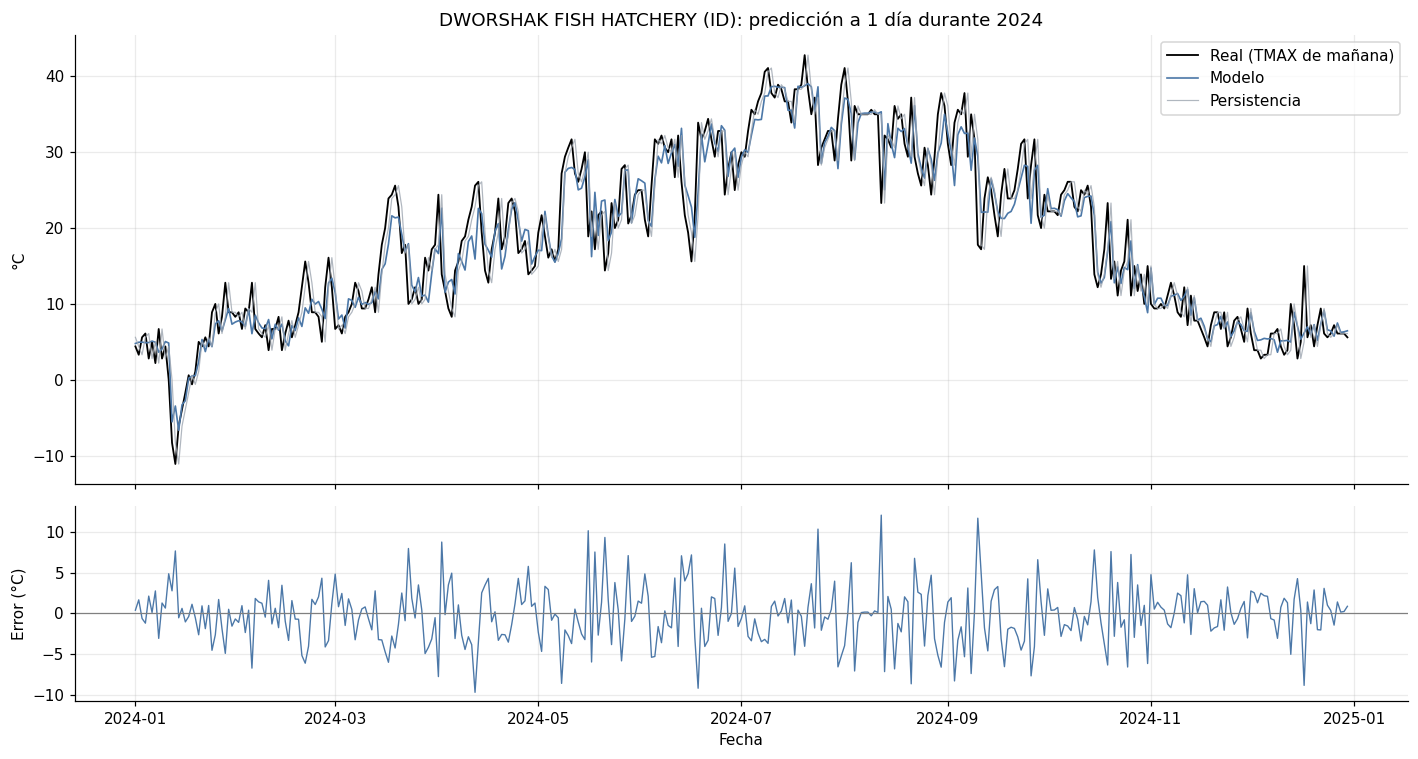

DWORSHAK FISH HATCHERY (ID): MAE del modelo 2.73 °C vs persistencia 2.87 °C (365 días)


In [ ]:
# 10.2 Serie diaria de una estación completa en el año de prueba
BACKTEST_STATION = None      # puedes escribir un ID, por ejemplo "USW00094846"

if BACKTEST_STATION is None:
    cand = (pred_test.filter(F.col("state") != "")
            .groupBy("station_id", "name", "state").count()
            .filter(F.col("count") >= 340).orderBy(F.desc("count")).limit(1).toPandas())
    BACKTEST_STATION = cand.loc[0, "station_id"]

serie = (pred_test.filter(F.col("station_id") == BACKTEST_STATION).orderBy("date").toPandas())
nombre = f"{serie.loc[0, 'name']} ({serie.loc[0, 'state']})"
mae_m = (serie["prediction"] - serie["label"]).abs().mean()
mae_p = (serie["tmax"] - serie["label"]).abs().mean()

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
axes[0].plot(serie["date"], serie["label"], color="black", lw=1.2, label="Real (TMAX de mañana)")
axes[0].plot(serie["date"], serie["prediction"], color="#4C78A8", lw=1.1, label="Modelo")
axes[0].plot(serie["date"], serie["tmax"], color="#9DA5B0", lw=0.8, alpha=0.8, label="Persistencia")
axes[0].set(title=f"{nombre}: predicción a 1 día durante {TEST_YEAR}", ylabel="°C"); axes[0].legend()
axes[1].plot(serie["date"], serie["prediction"] - serie["label"], color="#4C78A8", lw=0.9)
axes[1].axhline(0, color="gray", lw=0.8)
axes[1].set(ylabel="Error (°C)", xlabel="Fecha")
plt.tight_layout(); plt.show()
print(f"{nombre}: MAE del modelo {mae_m:.2f} °C vs persistencia {mae_p:.2f} °C ({len(serie)} días)")

In [ ]:
# 10.3 Escenarios nuevos (datos hipotéticos) pasados por el mismo Pipeline
def doy_trig(mes, dia):
    doy = pd.Timestamp(2024, mes, dia).dayofyear
    return np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)

escenarios = [
    dict(escenario="Phoenix, AZ · 15 jul · calor estable",        mes=7,  dia=15, lat=33.43, lon=-112.01, elev=337.0,  tmax=42.0, tmin=29.0, prcp=0.0,   tmax_lag1=41.5, tmax_mean7=41.8, tmin_mean7=29.3),
    dict(escenario="Minneapolis, MN · 15 ene · frío intenso",     mes=1,  dia=15, lat=44.88, lon=-93.23,  elev=256.0,  tmax=-6.0, tmin=-15.0, prcp=0.0,  tmax_lag1=-9.0, tmax_mean7=-8.0, tmin_mean7=-17.0),
    dict(escenario="Miami, FL · 10 oct · día lluvioso",           mes=10, dia=10, lat=25.79, lon=-80.29,  elev=4.0,    tmax=31.0, tmin=24.0, prcp=12.0,  tmax_lag1=30.5, tmax_mean7=30.8, tmin_mean7=24.5),
    dict(escenario="Denver, CO · 20 abr · calentamiento rápido",  mes=4,  dia=20, lat=39.85, lon=-104.66, elev=1655.0, tmax=18.0, tmin=3.0,  prcp=0.0,   tmax_lag1=9.0,  tmax_mean7=12.0, tmin_mean7=1.0),
    dict(escenario="Seattle, WA · 5 dic · nublado y húmedo",      mes=12, dia=5,  lat=47.45, lon=-122.31, elev=112.0,  tmax=8.0,  tmin=3.0,  prcp=6.0,   tmax_lag1=9.0,  tmax_mean7=8.5,  tmin_mean7=3.5),
    dict(escenario="Chicago, IL · 3 jun · SIN dato de lluvia",    mes=6,  dia=3,  lat=41.99, lon=-87.93,  elev=205.0,  tmax=24.0, tmin=14.0, prcp=np.nan, tmax_lag1=22.0, tmax_mean7=23.0, tmin_mean7=13.0),
]
filas = []
for e in escenarios:
    s, c = doy_trig(e["mes"], e["dia"])
    base = {k: v for k, v in e.items() if k not in ("mes", "dia")}
    filas.append({**base, "dtr": e["tmax"] - e["tmin"],
                  "prcp_missing": 1.0 if np.isnan(e["prcp"]) else 0.0, "doy_sin": s, "doy_cos": c})

esc_pdf = pd.DataFrame(filas)
esc_pdf[FEATURES] = esc_pdf[FEATURES].astype("float64")
esc_sdf = spark.createDataFrame(esc_pdf[["escenario"] + FEATURES])

esc_pred = final_model.transform(esc_sdf).select("escenario", "tmax", "tmin", "prcp", "prediction").toPandas()
esc_pred["prediccion_tmax_mañana"] = esc_pred["prediction"].round(1)
esc_pred["cambio_vs_hoy"] = (esc_pred["prediction"] - esc_pred["tmax"]).round(1)
display(esc_pred.drop(columns="prediction"))

,escenario,tmax,tmin,prcp,prediccion_tmax_mañana,cambio_vs_hoy
0,"Phoenix, AZ · 15 jul · calor estable",42.0,29.0,0.0,42.1,0.1
1,"Minneapolis, MN · 15 ene · frío intenso",-6.0,-15.0,0.0,-5.1,0.9
2,"Miami, FL · 10 oct · día lluvioso",31.0,24.0,12.0,30.4,-0.6
3,"Denver, CO · 20 abr · calentamiento rápido",18.0,3.0,0.0,18.4,0.4
4,"Seattle, WA · 5 dic · nublado y húmedo",8.0,3.0,6.0,7.6,-0.4
5,"Chicago, IL · 3 jun · SIN dato de lluvia",24.0,14.0,NaN,25.6,1.6


**Qué reviso en las predicciones**

- Que **ningún escenario produzca una temperatura físicamente absurda** y que el sentido del cambio sea razonable: en el caso con calentamiento reciente se espera una predicción cercana o superior a la de hoy; en un día de lluvia, valores cercanos o inferiores.
- Que el caso **sin dato de lluvia** produzca una predicción normal: eso confirma que la mediana calculada con el entrenamiento se aplica correctamente a datos nuevos dentro del `Pipeline`.
- En la estación completa, que el error no se concentre en una temporada y que el modelo no sea consistentemente peor que la persistencia en los días de cambio brusco.

## 11. Tablero de visualización con una herramienta administrada

### Herramienta elegida: Looker Studio

Elegí **Looker Studio** (Google) porque es un servicio **administrado y en la nube**: no se instala nada, se edita desde el navegador, se comparte con un enlace y se integra de forma natural con el ecosistema de Google que ya usa Colab (archivos CSV, Google Sheets, Drive). Es gratuito y permite construir tableros interactivos con filtros, mapas y tablas.

### Qué datos le llevo al tablero y por qué

Looker Studio **no es el lugar para procesar cien millones de filas**; su función es presentar. Por eso Spark hace el trabajo pesado y entrega **tres tablas agregadas y pequeñas**, calculadas sobre la base completa y no sobre la muestra:

| Archivo | Contenido | Granularidad | Para qué sirve |
|---------|-----------|--------------|----------------|
| `dash_clima_estado_mes.csv` | Temperaturas, lluvia y días de calor extremo | Estado × mes (todos los años) | Series de tiempo y comparación entre estados |
| `dash_estaciones.csv` | Climatología de cada estación con su ubicación | Estación | Mapa de estaciones |
| `dash_modelo_estado_mes.csv` | Error del modelo y de la persistencia en 2024 | Estado × mes | Páginas de desempeño del modelo |

**Decisión sobre los promedios.** Los archivos incluyen **sumas y conteos** (por ejemplo, `tmax_sum_c` y `station_days`) además de promedios ya calculados. Si el tablero promediara promedios, un estado con pocas observaciones pesaría igual que uno con muchas, y los filtros darían resultados incorrectos. Con sumas y conteos, Looker Studio calcula el promedio correcto bajo cualquier filtro con un campo calculado (`SUM(suma) / SUM(conteo)`).

In [ ]:
# 11.1 Tablas agregadas para el tablero (calculadas con Spark sobre toda la capa plata)
def add_month_start(pdf, year_col="year", month_col="month"):
    pdf["month_start"] = pd.to_datetime(
        dict(year=pdf[year_col], month=pdf[month_col], day=1)).dt.strftime("%Y-%m-%d")
    return pdf

silver_state = silver.filter(F.col("state") != "")
hot = (F.col("tmax") >= 35).cast("int")
rain = (F.col("prcp") >= 1).cast("int")

# --- Tabla 1: estado x mes
dash_state_month = (
    silver_state.groupBy("year", "month", "state")
    .agg(F.approx_count_distinct("station_id").alias("stations"),
         F.count("*").alias("station_days"),
         F.round(F.sum("tmax"), 1).alias("tmax_sum_c"),
         F.round(F.sum("tmin"), 1).alias("tmin_sum_c"),
         F.count("prcp").alias("prcp_obs_days"),
         F.round(F.sum("prcp"), 1).alias("prcp_sum_mm"),
         F.sum(F.when(F.col("prcp").isNotNull(), rain).otherwise(0)).alias("rain_days"),
         F.sum(hot).alias("hot_days_35c"),
         F.round(F.max("tmax"), 1).alias("max_tmax_c"),
         F.round(F.min("tmin"), 1).alias("min_tmin_c"))
    .toPandas()
)
dash_state_month = add_month_start(dash_state_month)
dash_state_month["avg_tmax_c"] = (dash_state_month["tmax_sum_c"] / dash_state_month["station_days"]).round(2)
dash_state_month["avg_tmin_c"] = (dash_state_month["tmin_sum_c"] / dash_state_month["station_days"]).round(2)
dash_state_month = dash_state_month.sort_values(["year", "month", "state"])

# --- Tabla 2: estaciones
dash_stations = (
    silver_state.groupBy("station_id", "name", "state", "lat", "lon", "elev")
    .agg(F.count("*").alias("station_days"),
         F.countDistinct("year").alias("years_with_data"),
         F.round(F.sum("tmax"), 1).alias("tmax_sum_c"),
         F.round(F.sum("tmin"), 1).alias("tmin_sum_c"),
         F.round(F.sum("prcp"), 1).alias("prcp_sum_mm"),
         F.count("prcp").alias("prcp_obs_days"),
         F.sum(hot).alias("hot_days_35c"))
    .filter(F.col("station_days") >= 180)
    .toPandas()
)
dash_stations["avg_tmax_c"] = (dash_stations["tmax_sum_c"] / dash_stations["station_days"]).round(2)
dash_stations["avg_tmin_c"] = (dash_stations["tmin_sum_c"] / dash_stations["station_days"]).round(2)
dash_stations["latlon"] = dash_stations["lat"].round(4).astype(str) + "," + dash_stations["lon"].round(4).astype(str)

# --- Tabla 3: desempeño del modelo en el año de prueba
dash_model = (
    pred_test.filter(F.col("state") != "").groupBy("state", "month")
    .agg(F.count("*").alias("n"),
         F.round(F.sum("label"), 1).alias("real_sum_c"),
         F.round(F.sum("prediction"), 1).alias("pred_sum_c"),
         F.round(F.sum(F.abs(F.col("label") - F.col("prediction"))), 1).alias("abs_err_model_sum"),
         F.round(F.sum(F.abs(F.col("label") - F.col("tmax"))), 1).alias("abs_err_persist_sum"))
    .toPandas()
)
dash_model["year"] = TEST_YEAR
dash_model = add_month_start(dash_model)
dash_model["mae_modelo_c"] = (dash_model["abs_err_model_sum"] / dash_model["n"]).round(3)
dash_model["mae_persistencia_c"] = (dash_model["abs_err_persist_sum"] / dash_model["n"]).round(3)
dash_model = dash_model.sort_values(["month", "state"])

DASH_DIR = EXPORT_DIR / "looker_studio"
DASH_DIR.mkdir(parents=True, exist_ok=True)
exports = {
    "dash_clima_estado_mes.csv": dash_state_month,
    "dash_estaciones.csv": dash_stations,
    "dash_modelo_estado_mes.csv": dash_model,
}
for fname, pdf in exports.items():
    pdf.to_csv(DASH_DIR / fname, index=False)
    size_mb = (DASH_DIR / fname).stat().st_size / 1024**2
    print(f"{fname}: {len(pdf):,} filas, {len(pdf.columns)} columnas, {size_mb:.2f} MB")

metrics_df.to_csv(EXPORT_DIR / "metricas_modelo_prueba.csv")
comparison.drop(columns="parametros").to_csv(EXPORT_DIR / "comparacion_modelos_validacion.csv", index=False)
ejemplos.to_csv(EXPORT_DIR / "predicciones_ejemplo.csv", index=False)
esc_pred.drop(columns="prediction").to_csv(EXPORT_DIR / "predicciones_escenarios.csv", index=False)
display(dash_state_month.head(3))

dash_clima_estado_mes.csv: 4,800 filas, 16 columnas, 0.40 MB
dash_estaciones.csv: 8,578 filas, 16 columnas, 0.97 MB
dash_modelo_estado_mes.csv: 600 filas, 11 columnas, 0.04 MB


,year,month,state,stations,station_days,tmax_sum_c,tmin_sum_c,prcp_obs_days,prcp_sum_mm,rain_days,hot_days_35c,max_tmax_c,min_tmin_c,month_start,avg_tmax_c,avg_tmin_c
150,2017,1,AK,295,8946,-90822.2,-160238.4,5189,14763.6,1440,0,13.5,-51.9,2017-01-01,-10.15,-17.91
333,2017,1,AL,109,3419,57891.9,18521.5,3093,22505.4,877,0,27.8,-15.6,2017-01-01,16.93,5.42
2486,2017,1,AR,116,3412,41698.3,6173.4,3201,7638.2,826,0,27.2,-18.9,2017-01-01,12.22,1.81


In [ ]:
# 11.2 Descarga de los CSV desde Colab (para subirlos a Looker Studio)
if IN_COLAB:
    from google.colab import files
    for fname in exports:
        files.download(str(DASH_DIR / fname))
else:
    print("Fuera de Colab: los archivos están en", DASH_DIR)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Publicación y evidencia

**Estado de publicación:** pendiente de completar.

**ENLACE AL TABLERO:**

**CAPTURAS DEL TABLERO:**

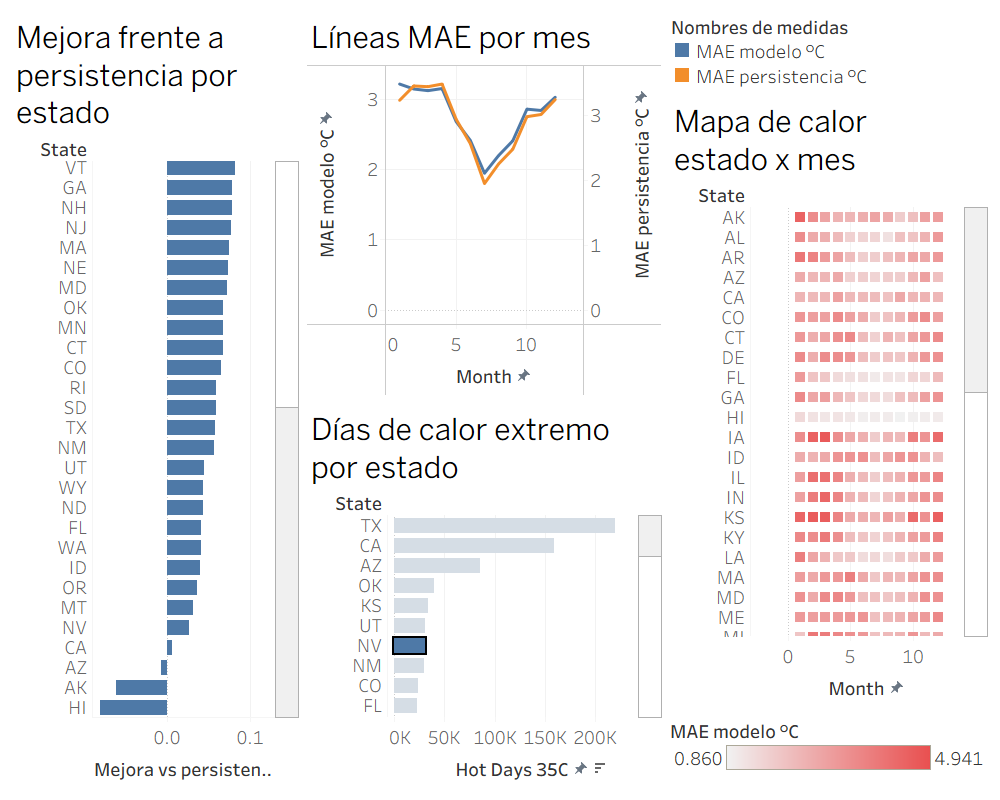

### Lectura del tablero

_(Completa esta parte después de construirlo, con lo que realmente observes. Preguntas guía:)_

1. ¿Qué estados y regiones concentran más días de calor extremo? ¿Coincide con la latitud y la elevación vistas en la sección 6?
2. ¿Cómo cambia la temperatura de un año a otro dentro del periodo? ¿Hay un año claramente más cálido?
3. ¿En qué meses y estados el modelo mejora más a la persistencia, y en cuáles casi no la mejora?
4. ¿La distribución geográfica de las estaciones introduce algún sesgo en lo que muestra el mapa (por ejemplo, zonas con pocas estaciones)?

## 12. Persistencia del modelo y reutilización

El modelo final se guarda **completo, con su `Pipeline`** (imputación, ensamblado, escalado y estimador). Así, cualquier persona puede cargarlo y predecir con datos nuevos que tengan las mismas columnas, sin reconstruir el preprocesamiento ni reentrenar. Para comprobar que el guardado funciona, lo vuelvo a cargar y verifico que las predicciones de los escenarios sean idénticas.

In [ ]:
model_dir = EXPORT_DIR / "modelo_tmax_siguiente_dia"
if model_dir.exists():
    shutil.rmtree(model_dir)
final_model.write().overwrite().save(str(model_dir))
model_zip = shutil.make_archive(str(EXPORT_DIR / "modelo_tmax_siguiente_dia"), "zip", root_dir=model_dir)
print("Modelo guardado en:", model_dir)
print("Archivo comprimido:", model_zip)

reloaded = PipelineModel.load(str(model_dir))
esc_again = reloaded.transform(esc_sdf).select("escenario", "prediction").toPandas()
same = np.allclose(esc_again["prediction"].values,
                   final_model.transform(esc_sdf).select("prediction").toPandas()["prediction"].values)
print("Las predicciones del modelo recargado coinciden con las del original:", same)

Modelo guardado en: /content/entregables/modelo_tmax_siguiente_dia
Archivo comprimido: /content/entregables/modelo_tmax_siguiente_dia.zip
Las predicciones del modelo recargado coinciden con las del original: True


## 13. Resultados, conclusiones y limitaciones

In [ ]:
# 13.1 Conclusiones redactadas con los valores de esta corrida
mm, mp = metrics_model, metrics_persist
veredicto = "supera" if mejora_rmse > 0 else "no supera"
peor_mes = int(by_month.sort_values("mae_modelo").iloc[-1]["month"])
mejor_mes = int(by_month.sort_values("mae_modelo").iloc[0]["month"])
meses = {1:"enero",2:"febrero",3:"marzo",4:"abril",5:"mayo",6:"junio",7:"julio",8:"agosto",
         9:"septiembre",10:"octubre",11:"noviembre",12:"diciembre"}
top_vars = ", ".join(importance_df["variable"].head(3))

display(Markdown(f'''
**Resultado del modelo.** El modelo final fue **{best_name}** con la configuración `{best_params}`, entrenado con datos de
{min(years_available)}–{VAL_YEAR} y evaluado en {TEST_YEAR} sobre **{n_test_pred:,}** observaciones nunca vistas.
Obtuvo un RMSE de **{mm["rmse"]:.2f} °C** y un MAE de **{mm["mae"]:.2f} °C**. La persistencia obtiene {mp["rmse"]:.2f} °C de RMSE
y {mp["mae"]:.2f} °C de MAE, de modo que el modelo **{veredicto}** a la referencia: la diferencia es de **{mejora_rmse:.1%}** en RMSE
y **{mejora_mae:.1%}** en MAE. El R² es {mm["r2"]:.3f}, pero como la estacionalidad por sí sola explica gran parte de la
varianza, la comparación relevante es la que se hace contra la persistencia.

**Dónde falla y dónde acierta.** El error es menor en **{meses[mejor_mes]}** y mayor en **{meses[peor_mes]}**. Las variables
más usadas por el modelo fueron: {top_vars}.

**Volumen procesado.** La capa bronce contiene **{n_bronze:,}** registros ({total_bytes/1e9:,.2f} GB comprimidos), de los cuales
**{n_silver:,}** estaciones-día de Estados Unidos pasaron los controles de calidad y **{n_gold:,}** tuvieron las variables
completas para el modelo.
'''))


**Resultado del modelo.** El modelo final fue **GBT** con la configuración `{'maxIter': 60, 'maxDepth': 6}`, entrenado con datos de
2017–2023 y evaluado en 2024 sobre **2,522,634** observaciones nunca vistas.
Obtuvo un RMSE de **3.64 °C** y un MAE de **2.75 °C**. La persistencia obtiene 4.01 °C de RMSE
y 2.92 °C de MAE, de modo que el modelo **supera** a la referencia: la diferencia es de **9.1%** en RMSE
y **5.8%** en MAE. El R² es 0.905, pero como la estacionalidad por sí sola explica gran parte de la
varianza, la comparación relevante es la que se hace contra la persistencia.

**Dónde falla y dónde acierta.** El error es menor en **julio** y mayor en **enero**. Las variables
más usadas por el modelo fueron: tmax, dtr, doy_cos.

**Volumen procesado.** La capa bronce contiene **301,099,069** registros (1.38 GB comprimidos), de los cuales
**21,757,659** estaciones-día de Estados Unidos pasaron los controles de calidad y **21,027,371** tuvieron las variables
completas para el modelo.




- Fuentes: [datos diarios por año de NOAA NCEI](https://www.ncei.noaa.gov/pub/data/ghcn/daily/by_year/), [catálogo de estaciones](https://www.ncei.noaa.gov/pub/data/ghcn/daily/ghcnd-stations.txt) y [documentación oficial](https://www.ncei.noaa.gov/pub/data/ghcn/daily/readme.txt).